# 🩺 당뇨병 발병 위험요인 분석 — 로지스틱 회귀

> 피마 인디언 여성 724명의 건강 검진 지표로 당뇨병 여부를 판별하는 로지스틱 회귀를
> **품질 점검 → EDA → 기준선 모형 → 가정 검정(로짓 선형성) → 체크포인트 비교 → 최종 보고**의 흐름으로 수행했습니다.
> 직선을 가정한 기준선 모형에서 **나이는 유의하지 않았지만**(p = 0.085), 가정 검정으로 **'오르다가 꺾이는' 곡선 관계**가 드러나자 혈당 다음으로 강한 위험요인이 됐습니다.
> 또 정확도(0.78)만 보면 좋은 모델이지만 **당뇨 환자의 40%를 놓친다**는 점을 확인하고, 선별검사 목적에 맞게 임계값을 조정했습니다.

| 항목 | 내용 |
|---|---|
| **데이터** | [Pima Indians Diabetes (Kaggle)](https://www.kaggle.com/datasets/uciml/pima-indians-diabetes-database) · 768행 → 결측 처리 후 724행 × 6개 지표 |
| **종속변수** | `Outcome` — 당뇨(1) 249명 / 정상(0) 475명 (34 : 66, 불균형) |
| **분석 질문** | ① 당뇨병 발병과 관련된 위험요인은 무엇인가? ② 나이의 위험은 직선적으로 늘어나는가? ③ 선별검사로 쓰려면 판정 기준(임계값)을 어떻게 정해야 하는가? |
| **주요 기법** | Mann-Whitney U · Box-Tidwell 로짓 선형성 검정 · 중심화 제곱항 · 후진소거 · AUC · 임계값 조정 |

### 📑 목차
0. **준비** — 라이브러리, 데이터 로드, 컬럼 의미
1. **PART 1. 데이터 품질 점검** — 숨어 있는 결측치(0값) 찾기 · 결측 처리 · 기술통계
2. **PART 2. EDA** — 단변량(불균형 확인) → 이변량(집단 비교) → 다변량(공선성) → 최종 변수 선택
3. **PART 3. 기준선 모형과 가정 검정** — 기준선 모형 → 로짓 선형성 진단 → 처방 루프 → 독립성
4. **PART 4. 로지스틱 회귀 모델링** — 전처리 체크포인트 비교 → 최종 모델 선택
5. **PART 5. 최종 모델 보고** — 계수 해석 · 분류 성능 · 임계값 조정
6. **📌 종합 인사이트**

> ⚙️ **사용 모듈** : `my_qtcheck` · `my_plot` · `my_stats` · `my_prep` · `my_logit` (helpers) · 데이터 로더 `jussam`

---
# 0. 준비

### (1) 라이브러리 참조

In [63]:
from jussam import load_data
from helpers import *

import numpy as np
from pandas import DataFrame, set_option
from IPython.display import display, Markdown

set_option("display.float_format", "{:,.3f}".format)   # 소수점 3자리로 출력

### (2) 데이터 가져오기

In [64]:
origin = load_data("pima_indians_diabetes")
print(f"데이터 크기 : {origin.shape}")
origin.head()

📚 이 데이터 세트는 원래 미국 국립 당뇨병·소화기·신장질환 연구소(National Institute of Diabetes and Digestive and Kidney Diseases)에서 제공한 것입니다. 이 데이터 세트의 목적은 데이터 세트에 포함된 특정 진단 측정값을 기반으로 환자의 당뇨병 여부를 진단적으로 예측하는 것입니다. 더 큰 데이터베이스에서 이러한 사례를 선택하는 데에는 몇 가지 제약 조건이 적용되었습니다. 특히, 여기에 포함된 모든 환자는 21세 이상의 피마 인디언 혈통을 가진 여성입니다. (출처: https://www.kaggle.com/datasets/uciml/pima-indians-diabetes-database)

field                     type    description
------------------------  ------  --------------------------------
Pregnancies               연속형  임신횟수
Glucose                   연속형  포도당 부하 검사 수치
BloodPressure             연속형  혈압
SkinThickness             연속형  팔 삼두근 뒤쪽의 피하지방 측정값
Insulin                   연속형  혈청 인슐린
BMI                       연속형  체질량 지수
DiabetesPedigreeFunction  연속형  당뇨 내력 가중치 값
Age                       연속형  나이
Outcome                   명목형  당뇨여부(0 또는 1)

데이터 크기 : (768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.600,0.627,50,1
1,1,85,66,29,0,26.600,0.351,31,0
2,8,183,64,0,0,23.300,0.672,32,1
3,1,89,66,23,94,28.100,0.167,21,0
4,0,137,40,35,168,43.100,2.288,33,1


### (3) 컬럼 의미를 정리한 딕셔너리

In [65]:
column_means = {
    "Pregnancies":              "임신 횟수",
    "Glucose":                  "포도당 부하 검사 수치",
    "BloodPressure":            "이완기 혈압(mmHg)",
    "SkinThickness":            "삼두근 피하지방 두께(mm)",
    "Insulin":                  "혈청 인슐린",
    "BMI":                      "체질량지수",
    "DiabetesPedigreeFunction": "당뇨 가족력 지수",
    "Age":                      "나이",
    "Outcome":                  "당뇨 여부(0/1)",
}

---
# PART 1. 데이터 품질 점검

### (1) 자료형 변환

- 종속변수 `Outcome`은 0 / 1로 저장돼 있지만 의미는 '정상 / 당뇨'인 **명목형**이다.

In [66]:
df1 = my_qtcheck.set_type(data=origin, as_category=["Outcome"])

<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype   
---  ------                    --------------  -----   
 0   Pregnancies               768 non-null    int32   
 1   Glucose                   768 non-null    int32   
 2   BloodPressure             768 non-null    int32   
 3   SkinThickness             768 non-null    int32   
 4   Insulin                   768 non-null    int32   
 5   BMI                       768 non-null    float32 
 6   DiabetesPedigreeFunction  768 non-null    float32 
 7   Age                       768 non-null    int32   
 8   Outcome                   768 non-null    category
dtypes: category(1), float32(2), int32(6)
memory usage: 24.9 KB


### (2) 중복 · 결측치 점검

In [67]:
df2 = my_qtcheck.check_duplicates(data=df1)
my_qtcheck.check_missing_values(data=df2)

중복된 행의 수: 0


,Missing Count,Missing Ratio (%)
Pregnancies,0,0.000
Glucose,0,0.000
BloodPressure,0,0.000
SkinThickness,0,0.000
Insulin,0,0.000
BMI,0,0.000
DiabetesPedigreeFunction,0,0.000
Age,0,0.000
Outcome,0,0.000


### (3) 연속형 변수 기술통계량

In [68]:
num_desc = my_qtcheck.numerical_summary(df2)
num_desc.T

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
count,768.000,768.000,768.000,768.000,768.000,768.000,768.000,768.000
mean,3.845,120.895,69.105,20.536,79.799,31.993,0.472,33.241
std,3.370,31.973,19.356,15.952,115.244,7.884,0.331,11.760
min,0.000,0.000,0.000,0.000,0.000,0.000,0.078,21.000
25%,1.000,99.000,62.000,0.000,0.000,27.300,0.244,24.000
50%,3.000,117.000,72.000,23.000,30.500,32.000,0.373,29.000
75%,6.000,140.250,80.000,32.000,127.250,36.600,0.626,41.000
max,17.000,199.000,122.000,99.000,846.000,67.100,2.420,81.000
rel_diff,0.282,0.033,0.040,0.107,1.616,0.000,0.267,0.146
rdiff_flag,diff,similar,similar,diff,large_diff,similar,diff,diff


### (4) 숨어 있는 결측치 — 0값을 결측치로 바꾸기

- 결측치 점검에서는 0건이었지만, 기술통계에서 **혈당 · 혈압 · 피부두께 · 인슐린 · BMI의 최솟값이 0**이다. 살아 있는 사람의 이 수치가 0일 수는 없으므로, **측정하지 않은 값을 0으로 기록한 것**으로 본다.
- 임신 횟수(`Pregnancies`)는 0이 실제로 가능하므로 대상에서 뺀다. 나이와 가족력 지수는 0이 없다.

In [69]:
missing = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]

df3 = df2.copy()
for col in missing:
    df3[col] = np.where(df3[col] > 0, df3[col], np.nan)    # 0 → 결측치

my_qtcheck.check_missing_values(data=df3)

,Missing Count,Missing Ratio (%)
Pregnancies,0,0.000
Glucose,5,0.651
BloodPressure,35,4.557
SkinThickness,227,29.557
Insulin,374,48.698
BMI,11,1.432
DiabetesPedigreeFunction,0,0.000
Age,0,0.000
Outcome,0,0.000


### (5) 결측치 처리

- **`SkinThickness`(29.6%) · `Insulin`(48.7%)** : 결측이 너무 많아 **변수 자체를 제거**한다. 절반 가까이를 하나의 값으로 채우면 변수가 가진 정보가 사라진다.
- **`Glucose`(0.7%) · `BloodPressure`(4.6%) · `BMI`(1.4%)** : 결측이 5% 미만이라 **해당 행을 제거**해도 안전하다.

In [70]:
df4 = df3.drop(columns=["SkinThickness", "Insulin"])     # 결측이 많은 변수 제거
df4 = df4.dropna().reset_index(drop=True)                # 결측이 적은 변수는 행 제거

print("처리 전 :", df3.shape, "→ 처리 후 :", df4.shape)
my_qtcheck.check_missing_values(data=df4)

처리 전 : (768, 9) → 처리 후 : (724, 7)


,Missing Count,Missing Ratio (%)
Pregnancies,0,0.000
Glucose,0,0.000
BloodPressure,0,0.000
BMI,0,0.000
DiabetesPedigreeFunction,0,0.000
Age,0,0.000
Outcome,0,0.000


### (6) 기술통계량 재확인

In [71]:
num_desc = my_qtcheck.numerical_summary(df4)
num_desc.T

,Pregnancies,Glucose,BloodPressure,BMI,DiabetesPedigreeFunction,Age
count,724.000,724.000,724.000,724.000,724.000,724.000
mean,3.866,121.883,72.401,32.467,0.475,33.351
std,3.363,30.750,12.380,6.889,0.332,11.765
min,0.000,44.000,24.000,18.200,0.078,21.000
25%,1.000,99.750,64.000,27.500,0.245,24.000
50%,3.000,117.000,72.000,32.400,0.379,29.000
75%,6.000,142.000,80.000,36.600,0.627,41.000
max,17.000,199.000,122.000,67.100,2.420,81.000
rel_diff,0.289,0.042,0.006,0.002,0.253,0.150
rdiff_flag,diff,similar,similar,similar,diff,diff


---
##### 💡 인사이트 — 품질 점검 결과

| 점검 항목 | 결과 |
|---|---|
| 중복 | 0건 |
| 결측치 (표면) | 0건 → 하지만 **0값으로 숨어 있었다** |
| 숨은 결측치 | `Insulin` 374건(48.7%) · `SkinThickness` 227건(29.6%) · `BloodPressure` 35건 · `BMI` 11건 · `Glucose` 5건 |
| 처리 | 결측이 많은 2개 변수 제거, 나머지는 결측 행 제거 → **768행 → 724행** (5.7% 감소) |
| 남은 변수 | 6개 (`Pregnancies` · `Glucose` · `BloodPressure` · `BMI` · `DiabetesPedigreeFunction` · `Age`) |

- `check_missing_values()`는 결측을 **0건**으로 보고했지만, 기술통계의 **최솟값 0**에서 측정하지 않은 값이 0으로 기록됐다는 것을 찾아냈다. 결측치 점검 함수만 믿으면 놓쳤을 문제다.
- 가족력 지수(왜도 1.92) · 나이(1.09) · 임신 횟수(0.91)는 오른쪽으로 치우쳐 있지만, **로지스틱 회귀는 선형회귀와 달리 잔차의 정규성 · 등분산성을 가정하지 않으므로** 왜도만으로 변환하지 않는다. 변환은 PART 3의 로짓 선형성 검정에서 필요할 때만 한다.
- `BloodPressure`의 최솟값 24mmHg는 비현실적으로 낮지만, 0만 결측으로 보고 나머지는 실측값으로 인정했다.
- **이상치는 대체하지 않는다.** 의료 데이터의 극단값(혈당 199, BMI 67 등)은 측정 오류가 아니라 실제 환자의 상태이고, 당뇨 판별에 가장 중요한 신호다. 생리적으로 불가능한 값(0)만 결측으로 처리했다.

---

# PART 2. 탐색적 데이터 분석(EDA)

### (1) 변수 유형 분류

In [72]:
target = "Outcome"                                            # 종속변수
nominal_cols = my_qtcheck.get_categorical_column_names(df4)   # 명목형 변수
continuous_cols = my_qtcheck.get_number_column_names(df4)     # 연속형 변수
nominal_cols.remove(target)                                   # 종속변수는 명목형 목록에서 제외

print("종속변수 :", target)
print("명목형   :", nominal_cols)
print("연속형   :", continuous_cols)

종속변수 : Outcome
명목형   : []
연속형   : ['Pregnancies', 'Glucose', 'BloodPressure', 'BMI', 'DiabetesPedigreeFunction', 'Age']


## 2-1. 단변량 분석

### (1) 종속변수 — 범주 비율(균형 여부)

- 로지스틱 회귀에서는 종속변수의 **범주 비율**을 먼저 본다. 비율이 한쪽으로 치우치면 정확도만으로 모델을 평가할 수 없다.

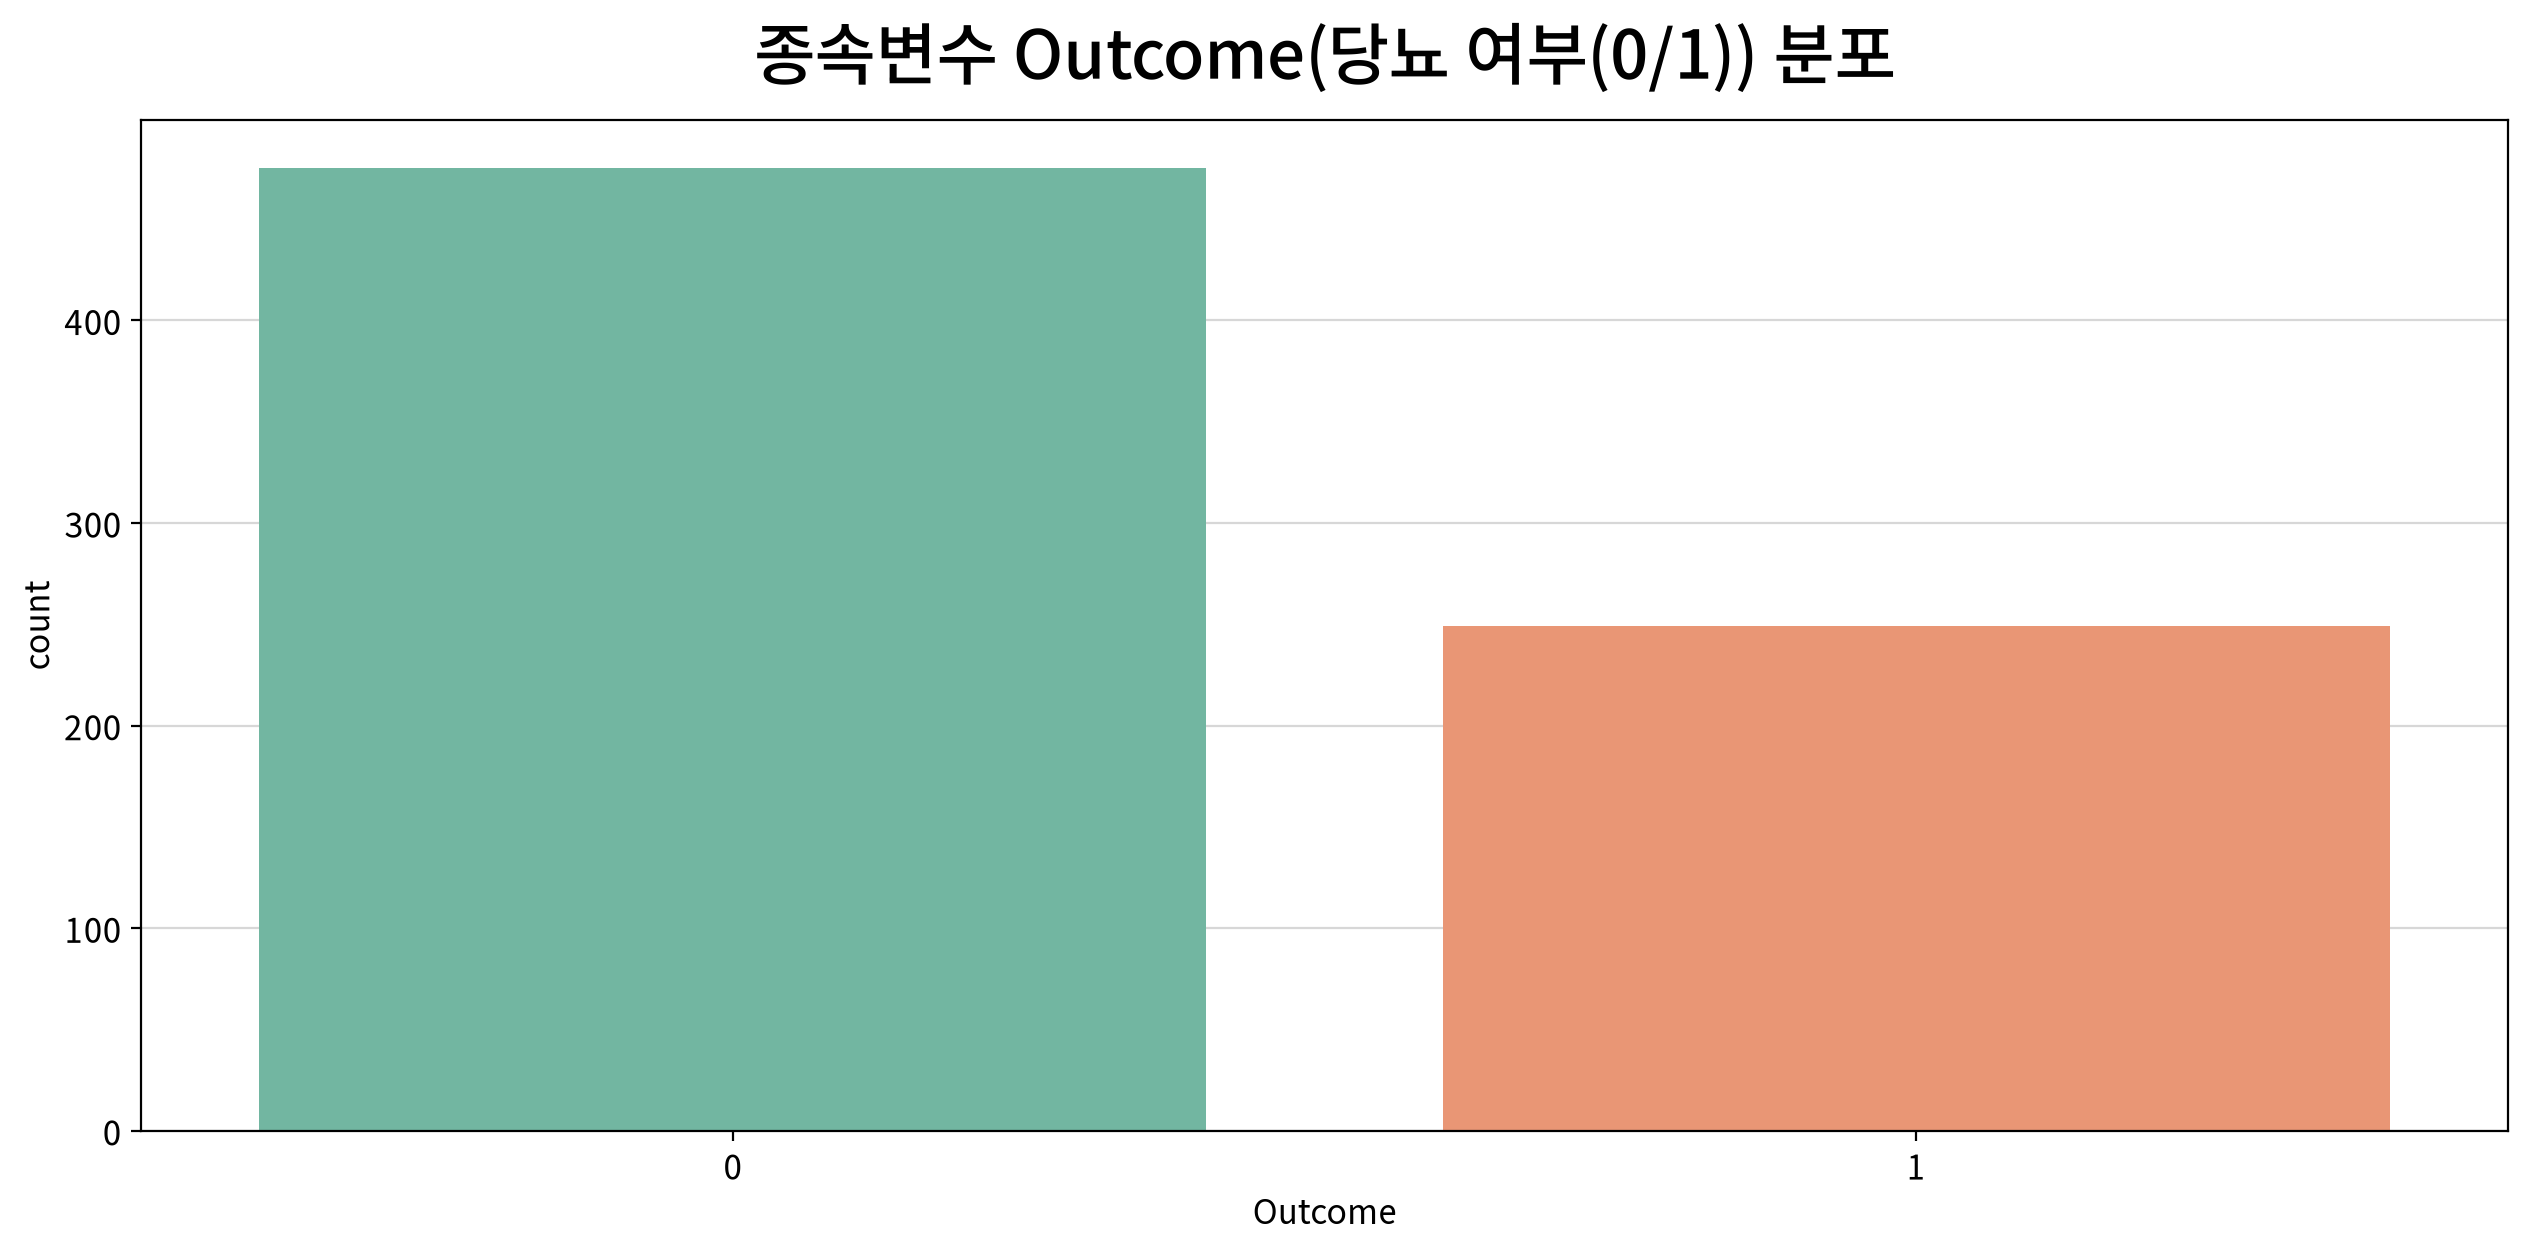

,빈도,비율
Outcome,,
0,475,0.656
1,249,0.344


In [73]:
my_plot.countplot(data=df4, x=target, hue=target, palette="Set2",
                  title=f"종속변수 {target}({column_means[target]}) 분포")

freq = df4[target].value_counts().rename("빈도").to_frame()
freq["비율"] = df4[target].value_counts(normalize=True)
freq

---
##### 💡 인사이트

| 점검 항목 | `Outcome` 관찰값 |
|---|---|
| 범주 수 | 2 (정상 0 / 당뇨 1) → **이분형**이므로 로지스틱 회귀 적용 가능 |
| 비율 | 정상 475명(65.6%) · 당뇨 249명(34.4%) |
| 균형 여부 | **불균형** (약 2 : 1) |

- **정확도의 함정에 주의해야 하는 데이터**다. 무조건 '정상'이라고만 답하는 게으른 모델도 정확도가 **65.6%** 나온다.
  - 즉 정확도 65.6%가 이 데이터의 **바닥값**이고, 모델은 정확도만이 아니라 **당뇨 환자를 얼마나 찾아내는지(재현율)** 로 함께 평가해야 한다.

---

### (2) 연속형 독립변수 분포

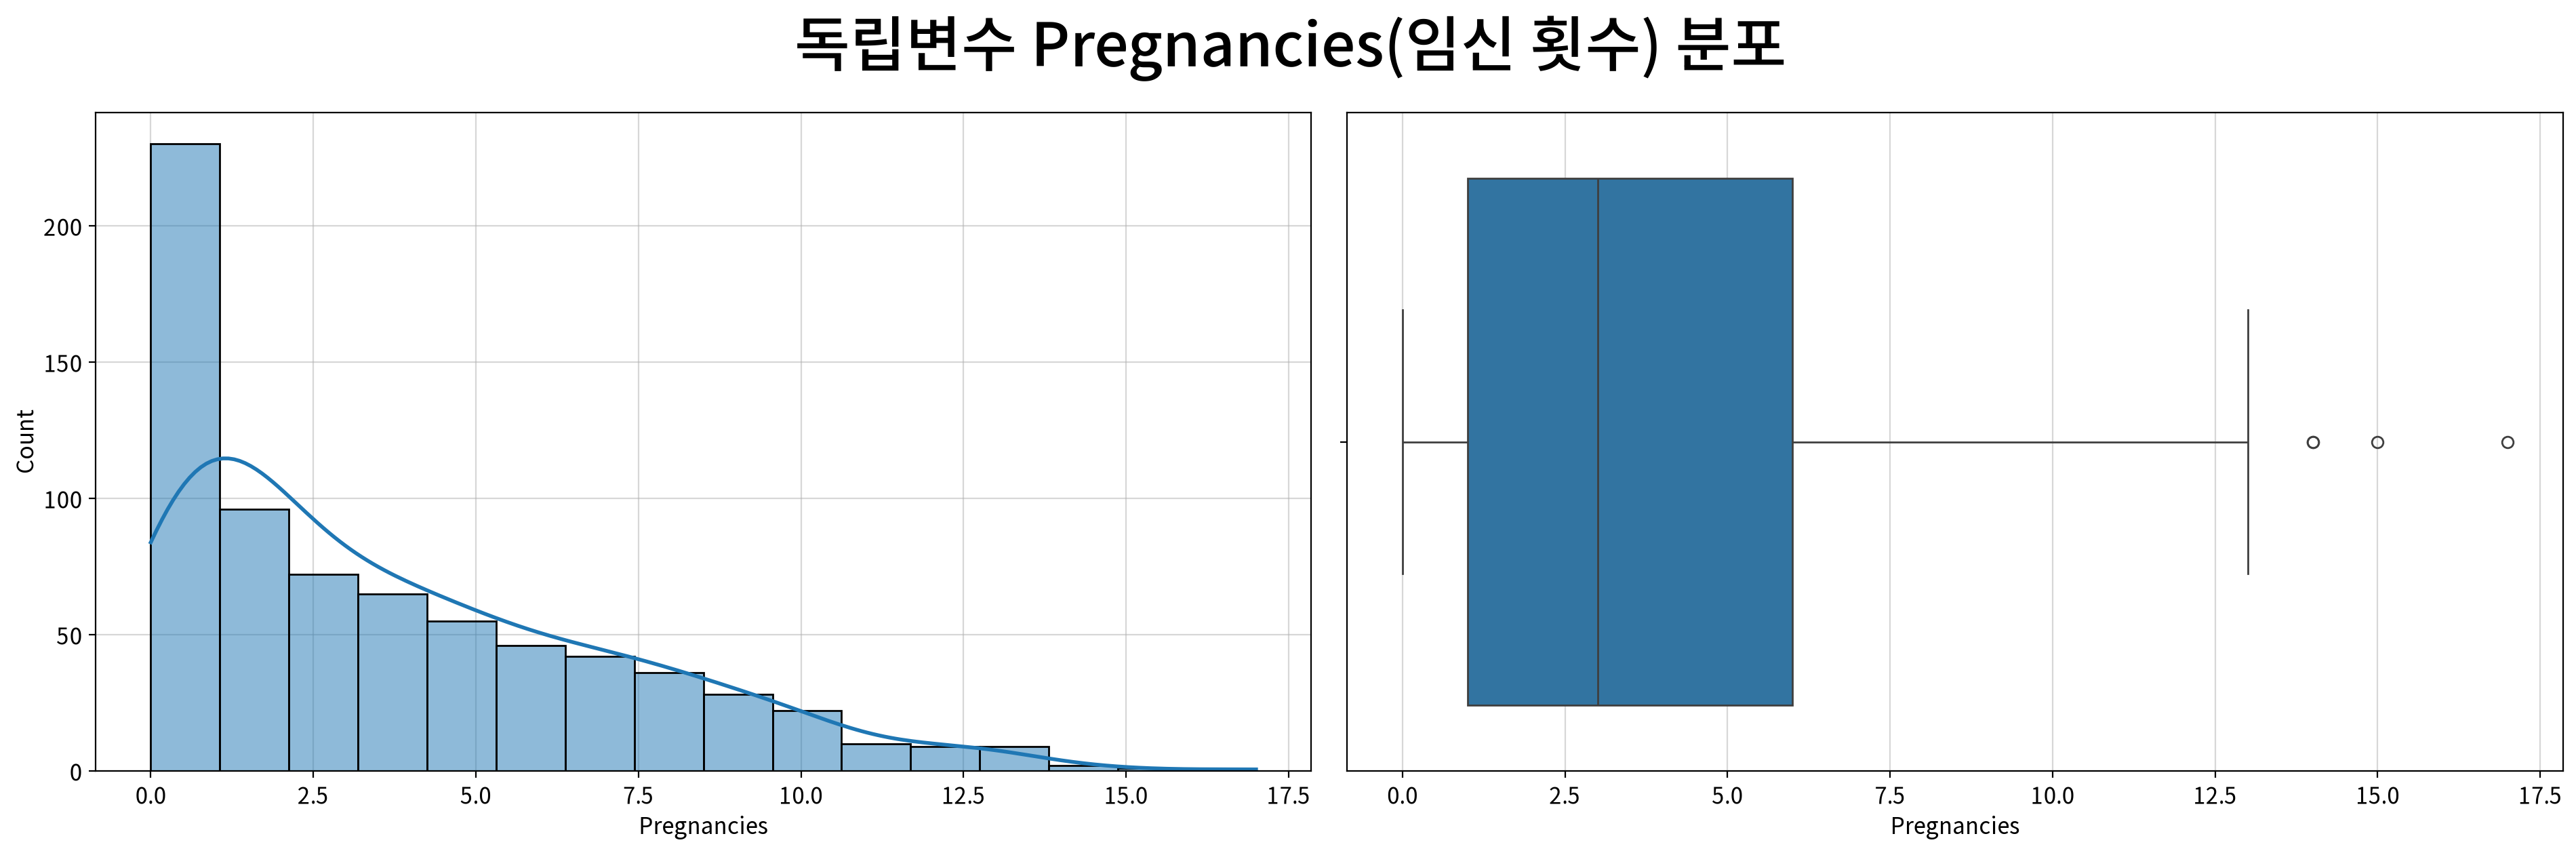

,Pregnancies
count,724.000
mean,3.866
std,3.363
min,0.000
25%,1.000
50%,3.000
75%,6.000
max,17.000
rel_diff,0.289
rdiff_flag,diff


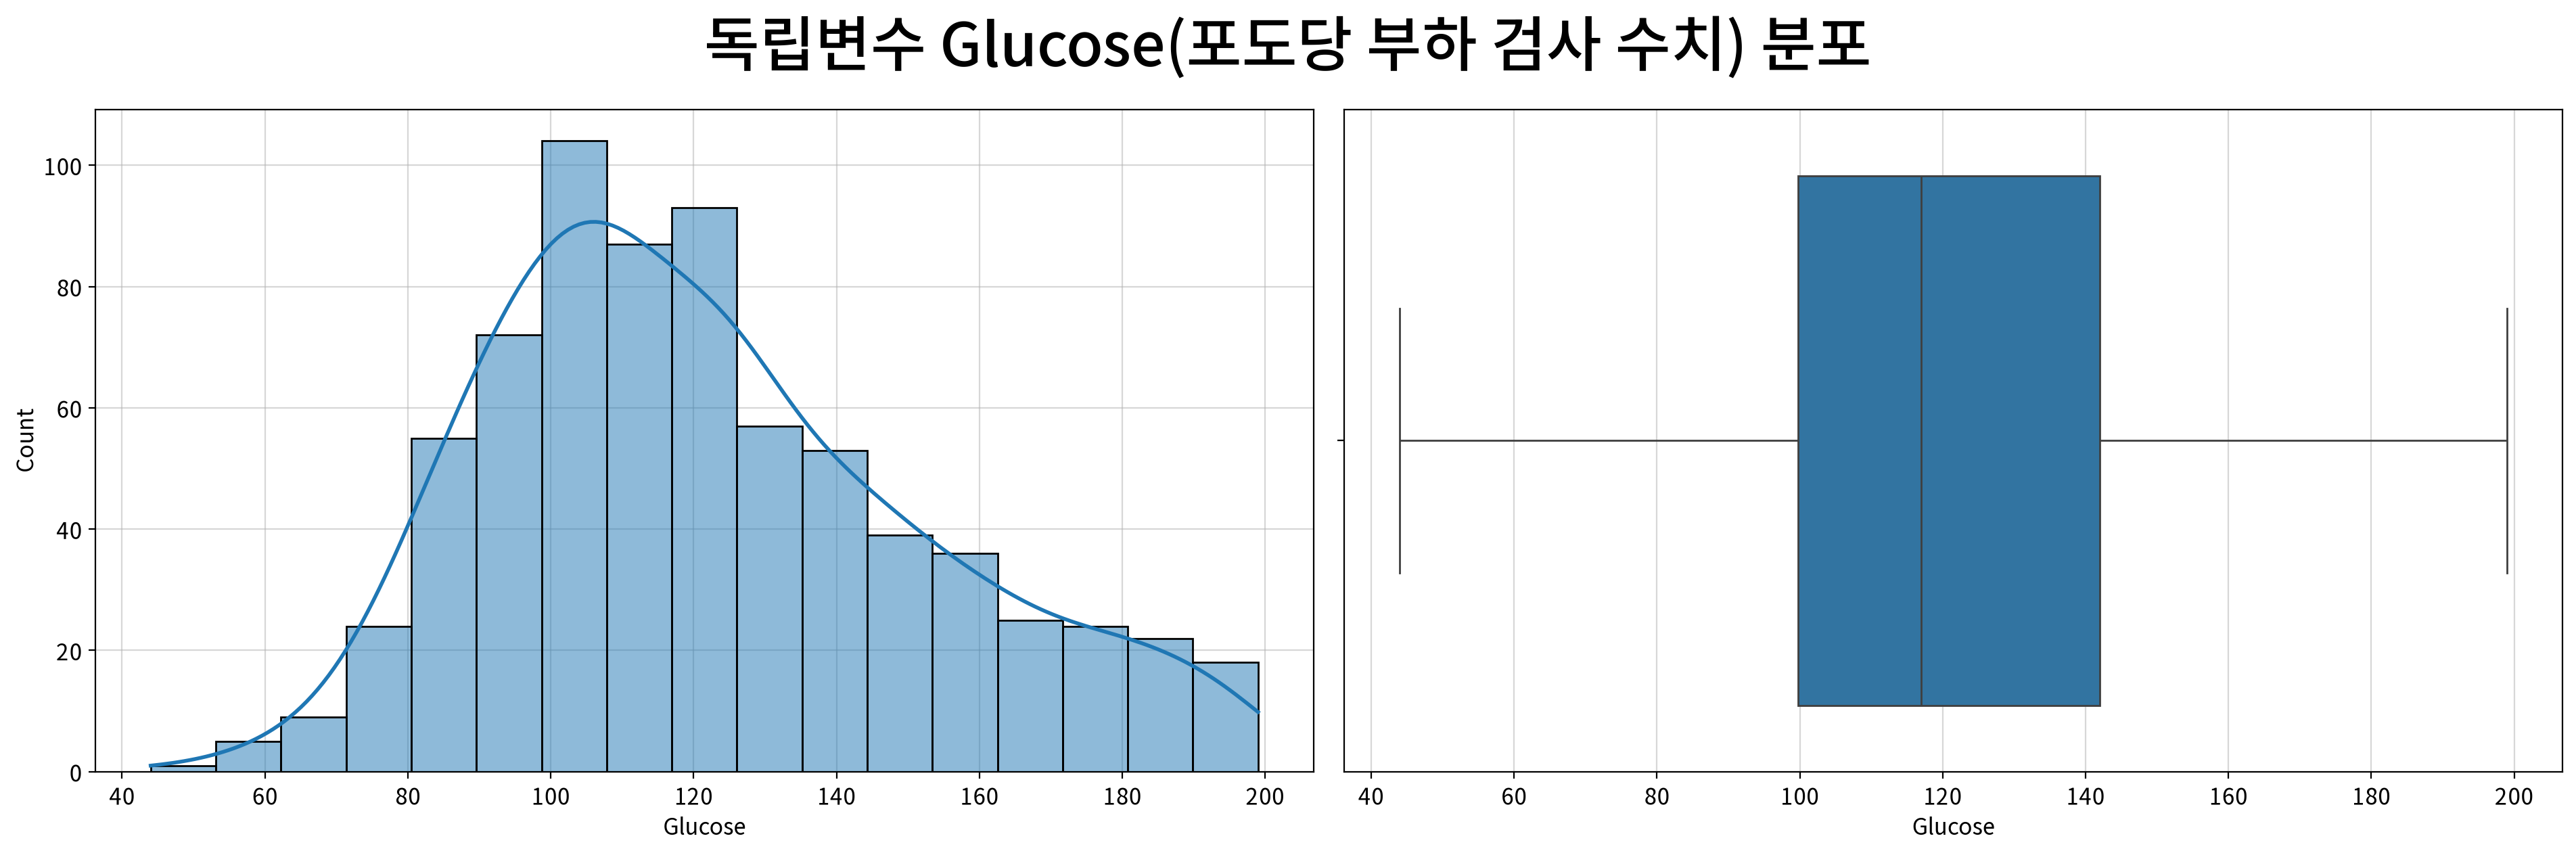

,Glucose
count,724.000
mean,121.883
std,30.750
min,44.000
25%,99.750
50%,117.000
75%,142.000
max,199.000
rel_diff,0.042
rdiff_flag,similar


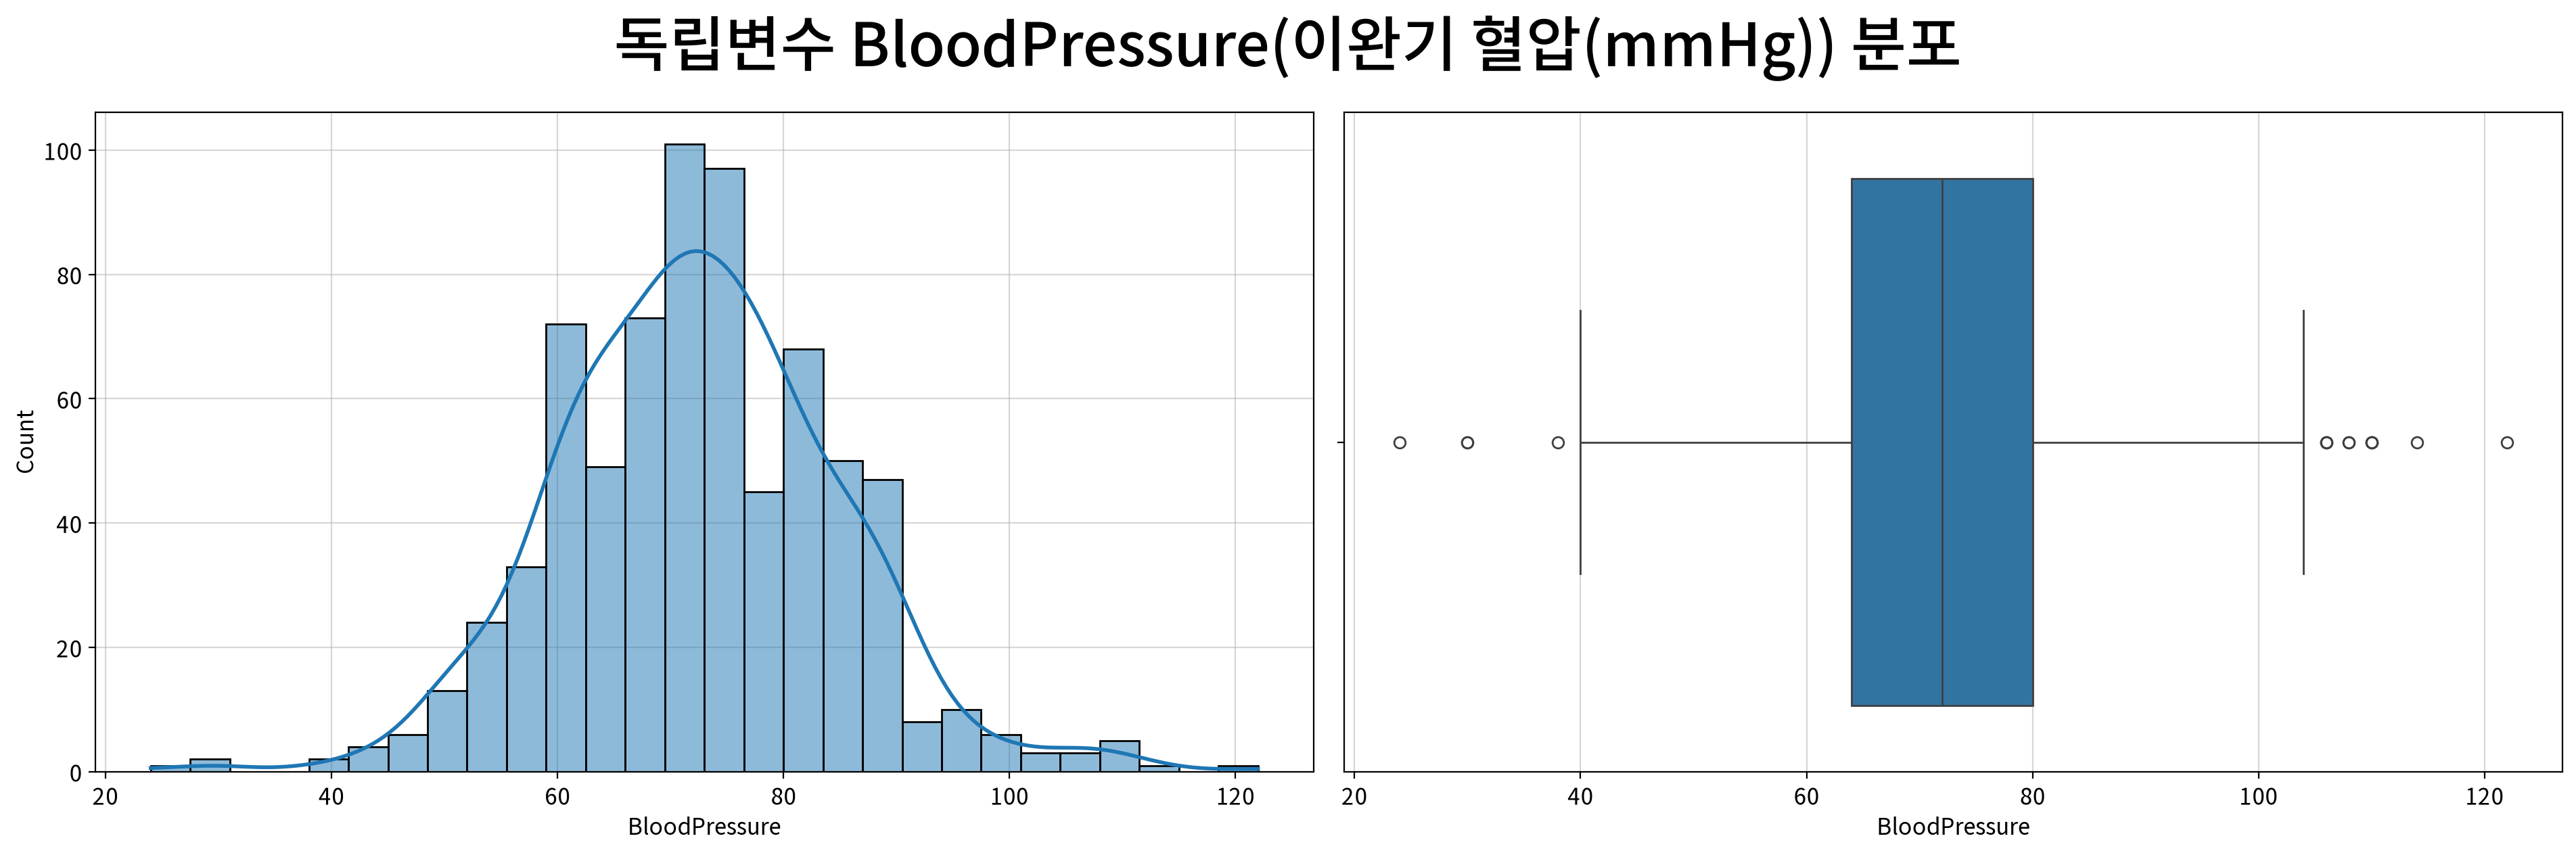

,BloodPressure
count,724.000
mean,72.401
std,12.380
min,24.000
25%,64.000
50%,72.000
75%,80.000
max,122.000
rel_diff,0.006
rdiff_flag,similar


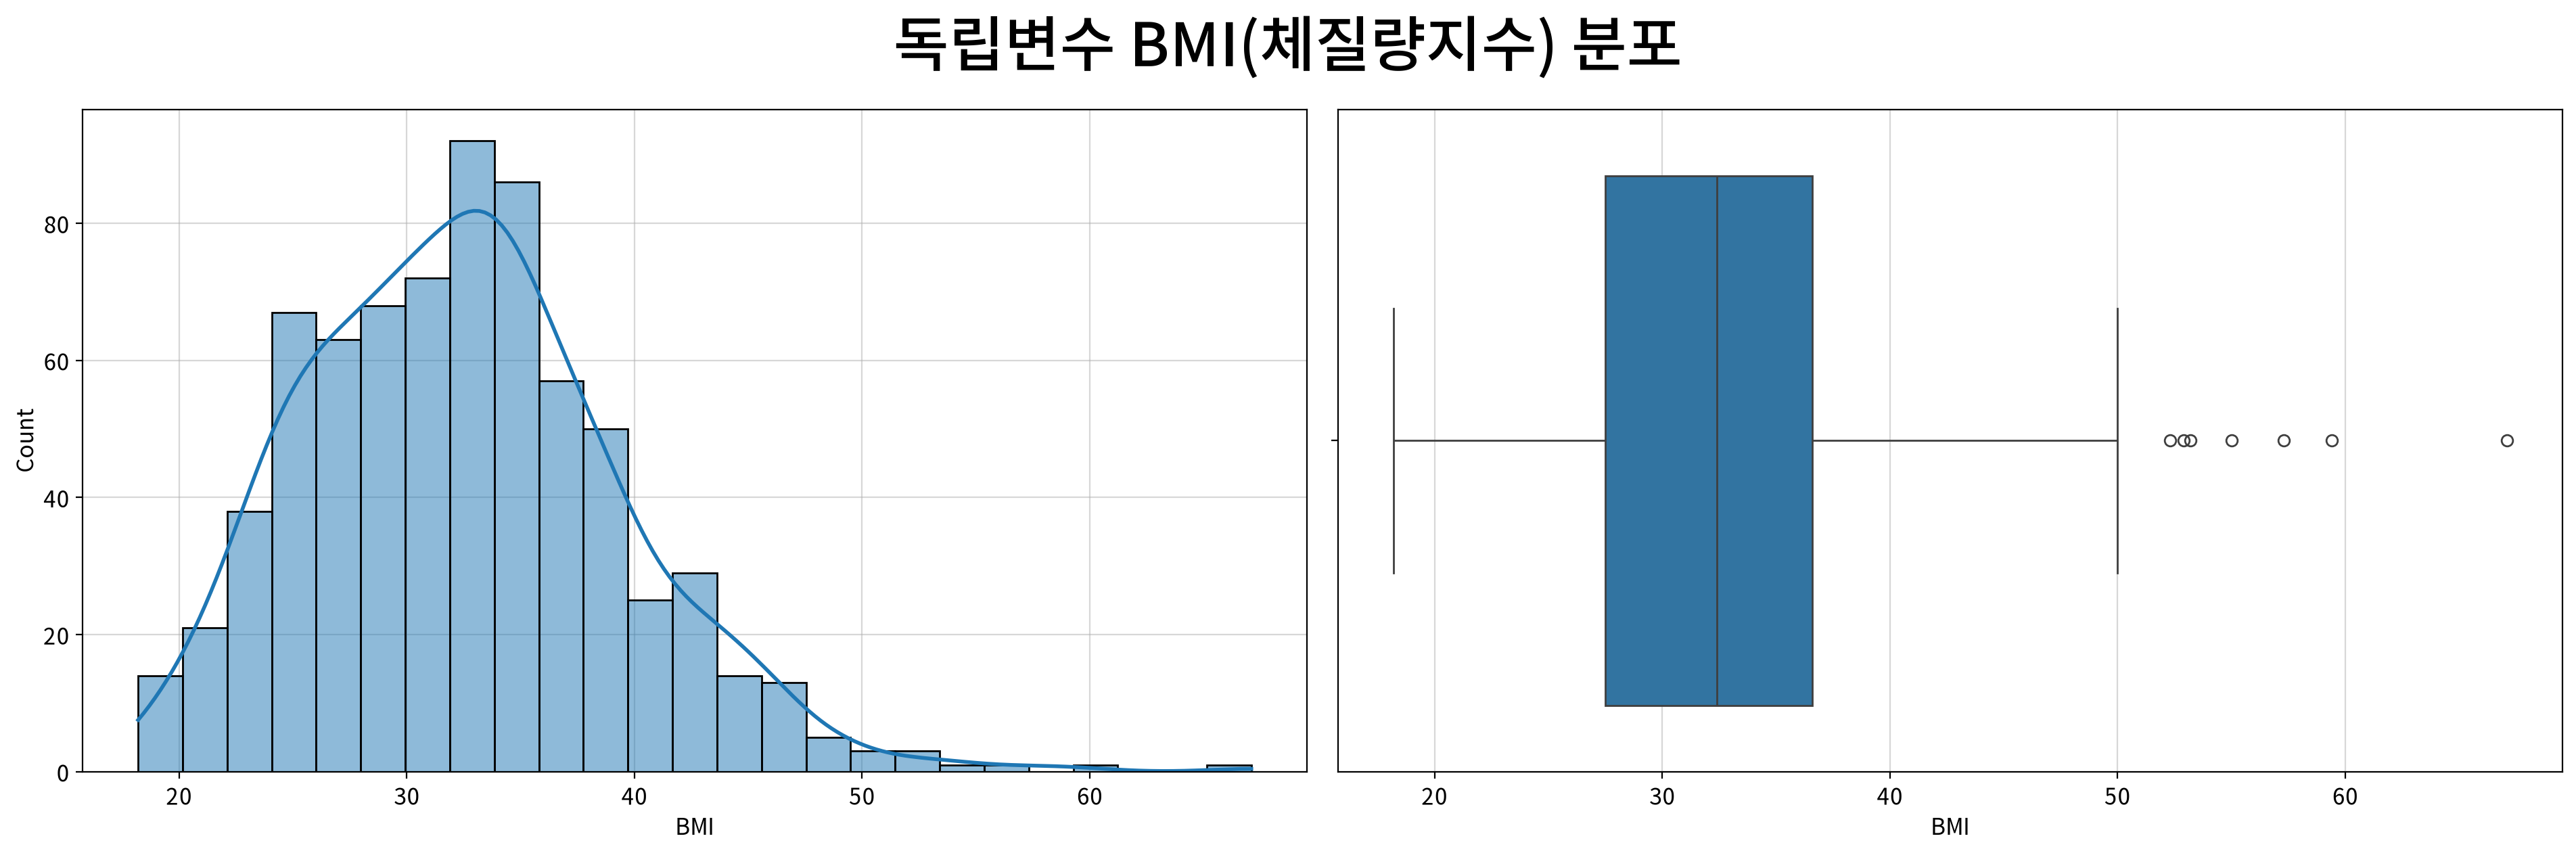

,BMI
count,724.000
mean,32.467
std,6.889
min,18.200
25%,27.500
50%,32.400
75%,36.600
max,67.100
rel_diff,0.002
rdiff_flag,similar


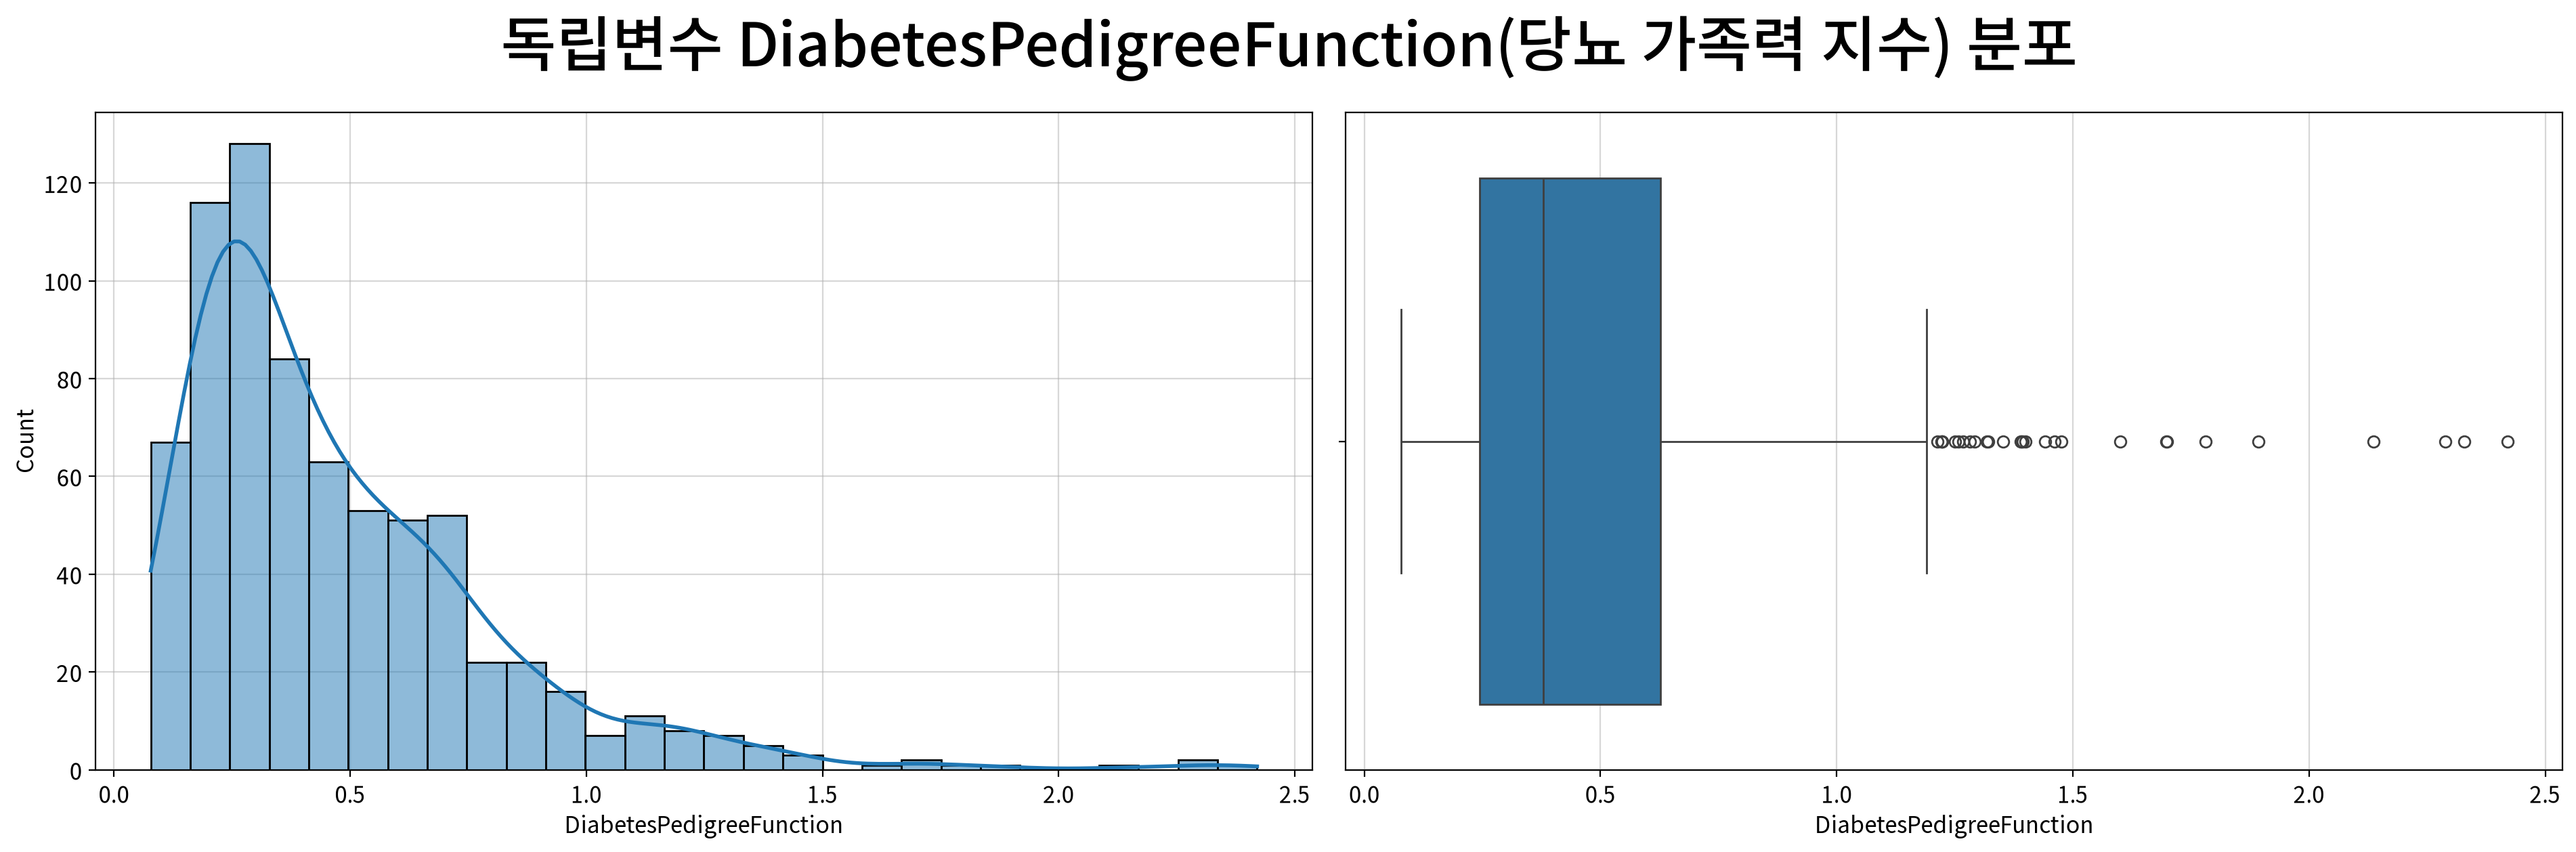

,DiabetesPedigreeFunction
count,724.000
mean,0.475
std,0.332
min,0.078
25%,0.245
50%,0.379
75%,0.627
max,2.420
rel_diff,0.253
rdiff_flag,diff


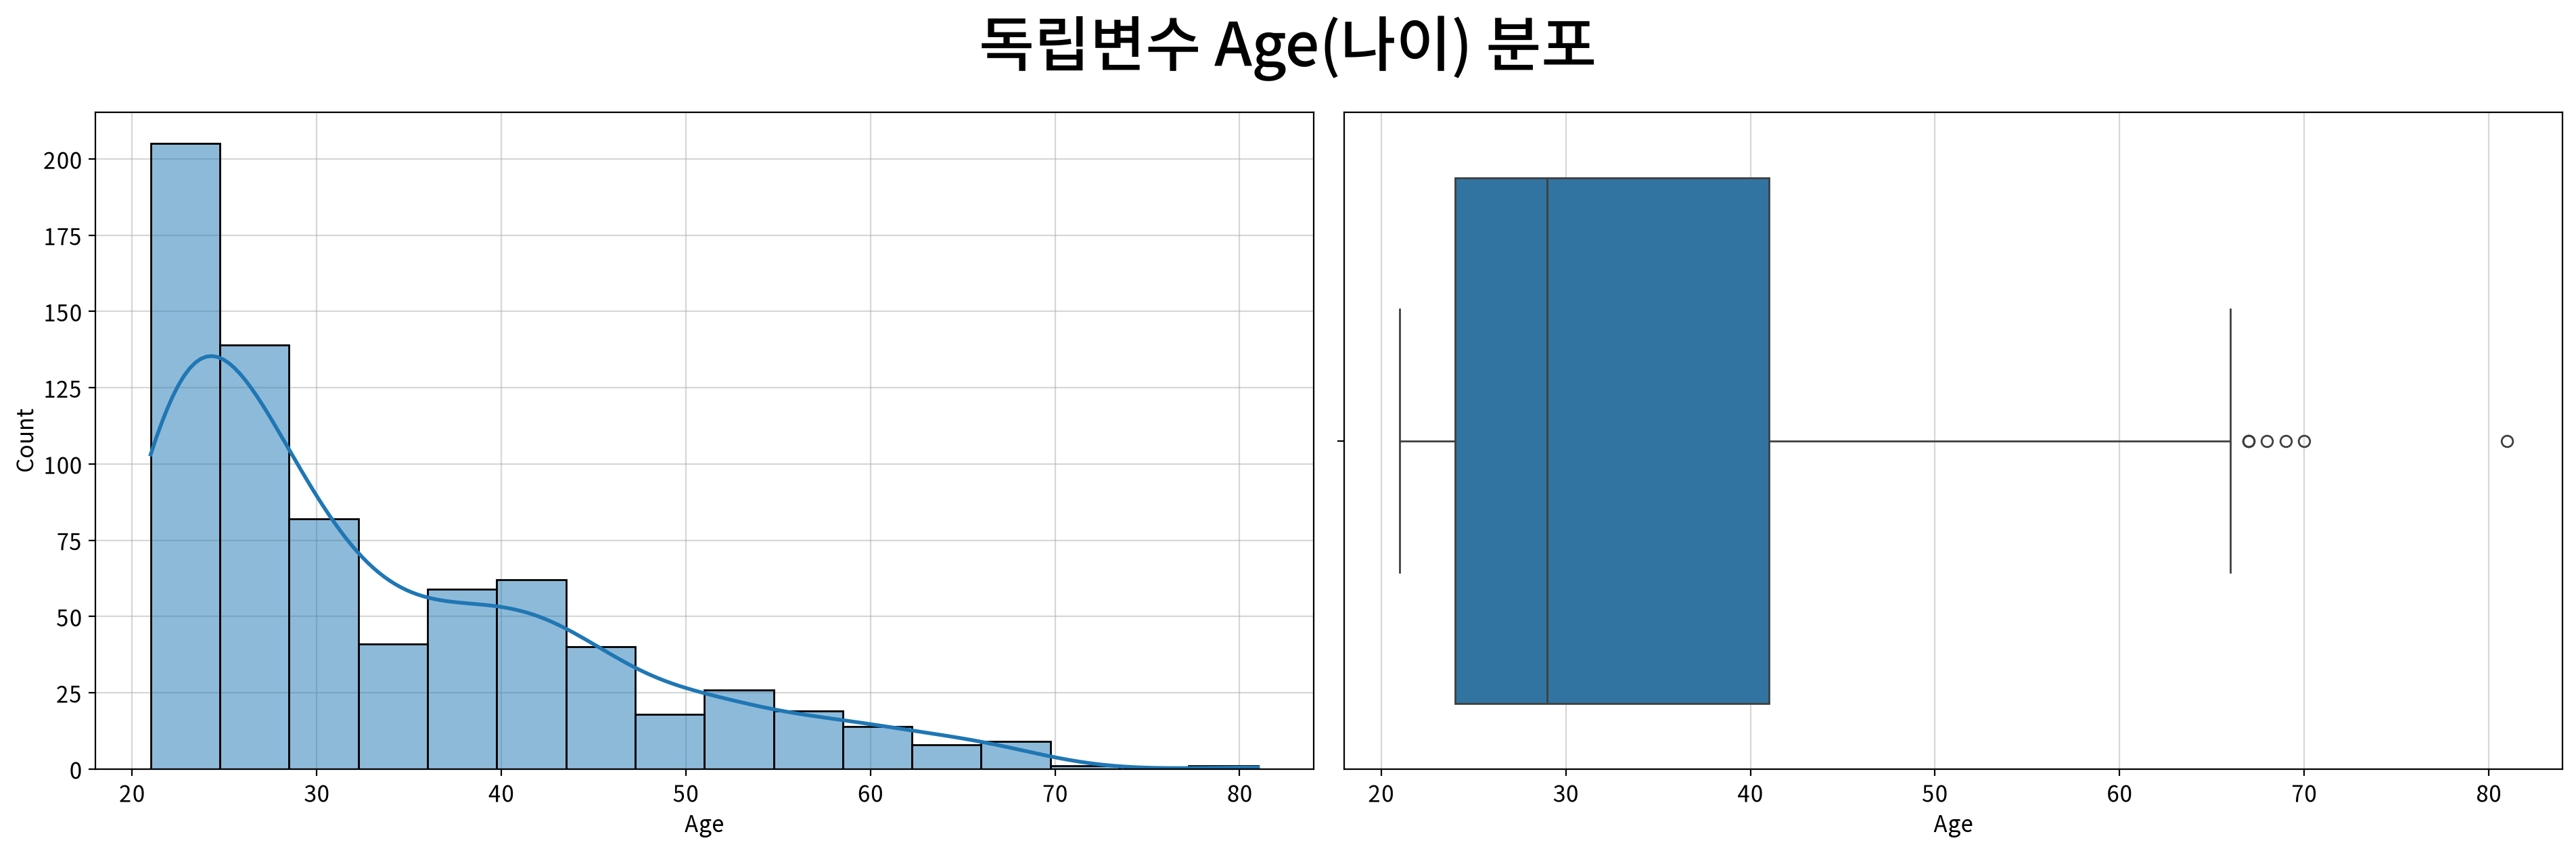

,Age
count,724.000
mean,33.351
std,11.765
min,21.000
25%,24.000
50%,29.000
75%,41.000
max,81.000
rel_diff,0.150
rdiff_flag,diff


In [74]:
for f in continuous_cols:
    fig, ax = my_plot.init(rows=1, cols=2, width=960, height=640,
                           title=f"독립변수 {f}({column_means[f]}) 분포")
    my_plot.histplot(data=df4, x=f, kde=True, ax=ax[0])
    my_plot.boxplot(data=df4, x=f, ax=ax[1])
    my_plot.show()

    display(num_desc[num_desc.index == f].T)

---
##### 💡 인사이트

| 변수 | 분포 모양 (왜도) | 이상치 | 판단 |
|---|---|---|---|
| `Pregnancies` | 우편향 (0.91), 0~2회에 몰림 | 0.6% | 변환하지 않음 |
| `Glucose` | 약한 우편향 (0.53) | 0% | 변환하지 않음 |
| `BloodPressure` | 대칭 (0.14) | 1.9% | 변환하지 않음 |
| `BMI` | 약한 우편향 (0.60) | 1.0% | 변환하지 않음 |
| `DiabetesPedigreeFunction` | 강한 우편향 (1.92), 0.2~0.6에 몰림 | 3.9% | 변환하지 않음 |
| `Age` | 우편향 (1.09), 20대에 몰림 | 1.0% | 변환하지 않음 |

- 치우친 변수가 있지만 로지스틱 회귀에서는 **왜도가 변환의 기준이 아니다.** 로짓과의 관계가 직선인지가 기준이며, PART 3에서 검정한다.
- 나이는 20대가 많고 60대 이상은 적다. 고령 구간의 추정은 표본이 적어 불안정할 수 있다.

---

## 2-2. 이변량 분석 — 당뇨 집단과 정상 집단은 다른가?

- 종속변수가 명목형(2집단)이므로 상관분석 대신 **독립표본 검정**으로 "이 변수가 당뇨와 관련이 있는가"를 본다.
- 정규성 · 등분산성에 따라 **t / Welch / Mann-Whitney U**를 자동 선택한다.

#### ▶︎ Pregnancies(임신 횟수) → Outcome

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

0 vs. 1: Mann-Whitney-Wilcoxon test two-sided, P_val:3.441e-08 U_stat=4.449e+04


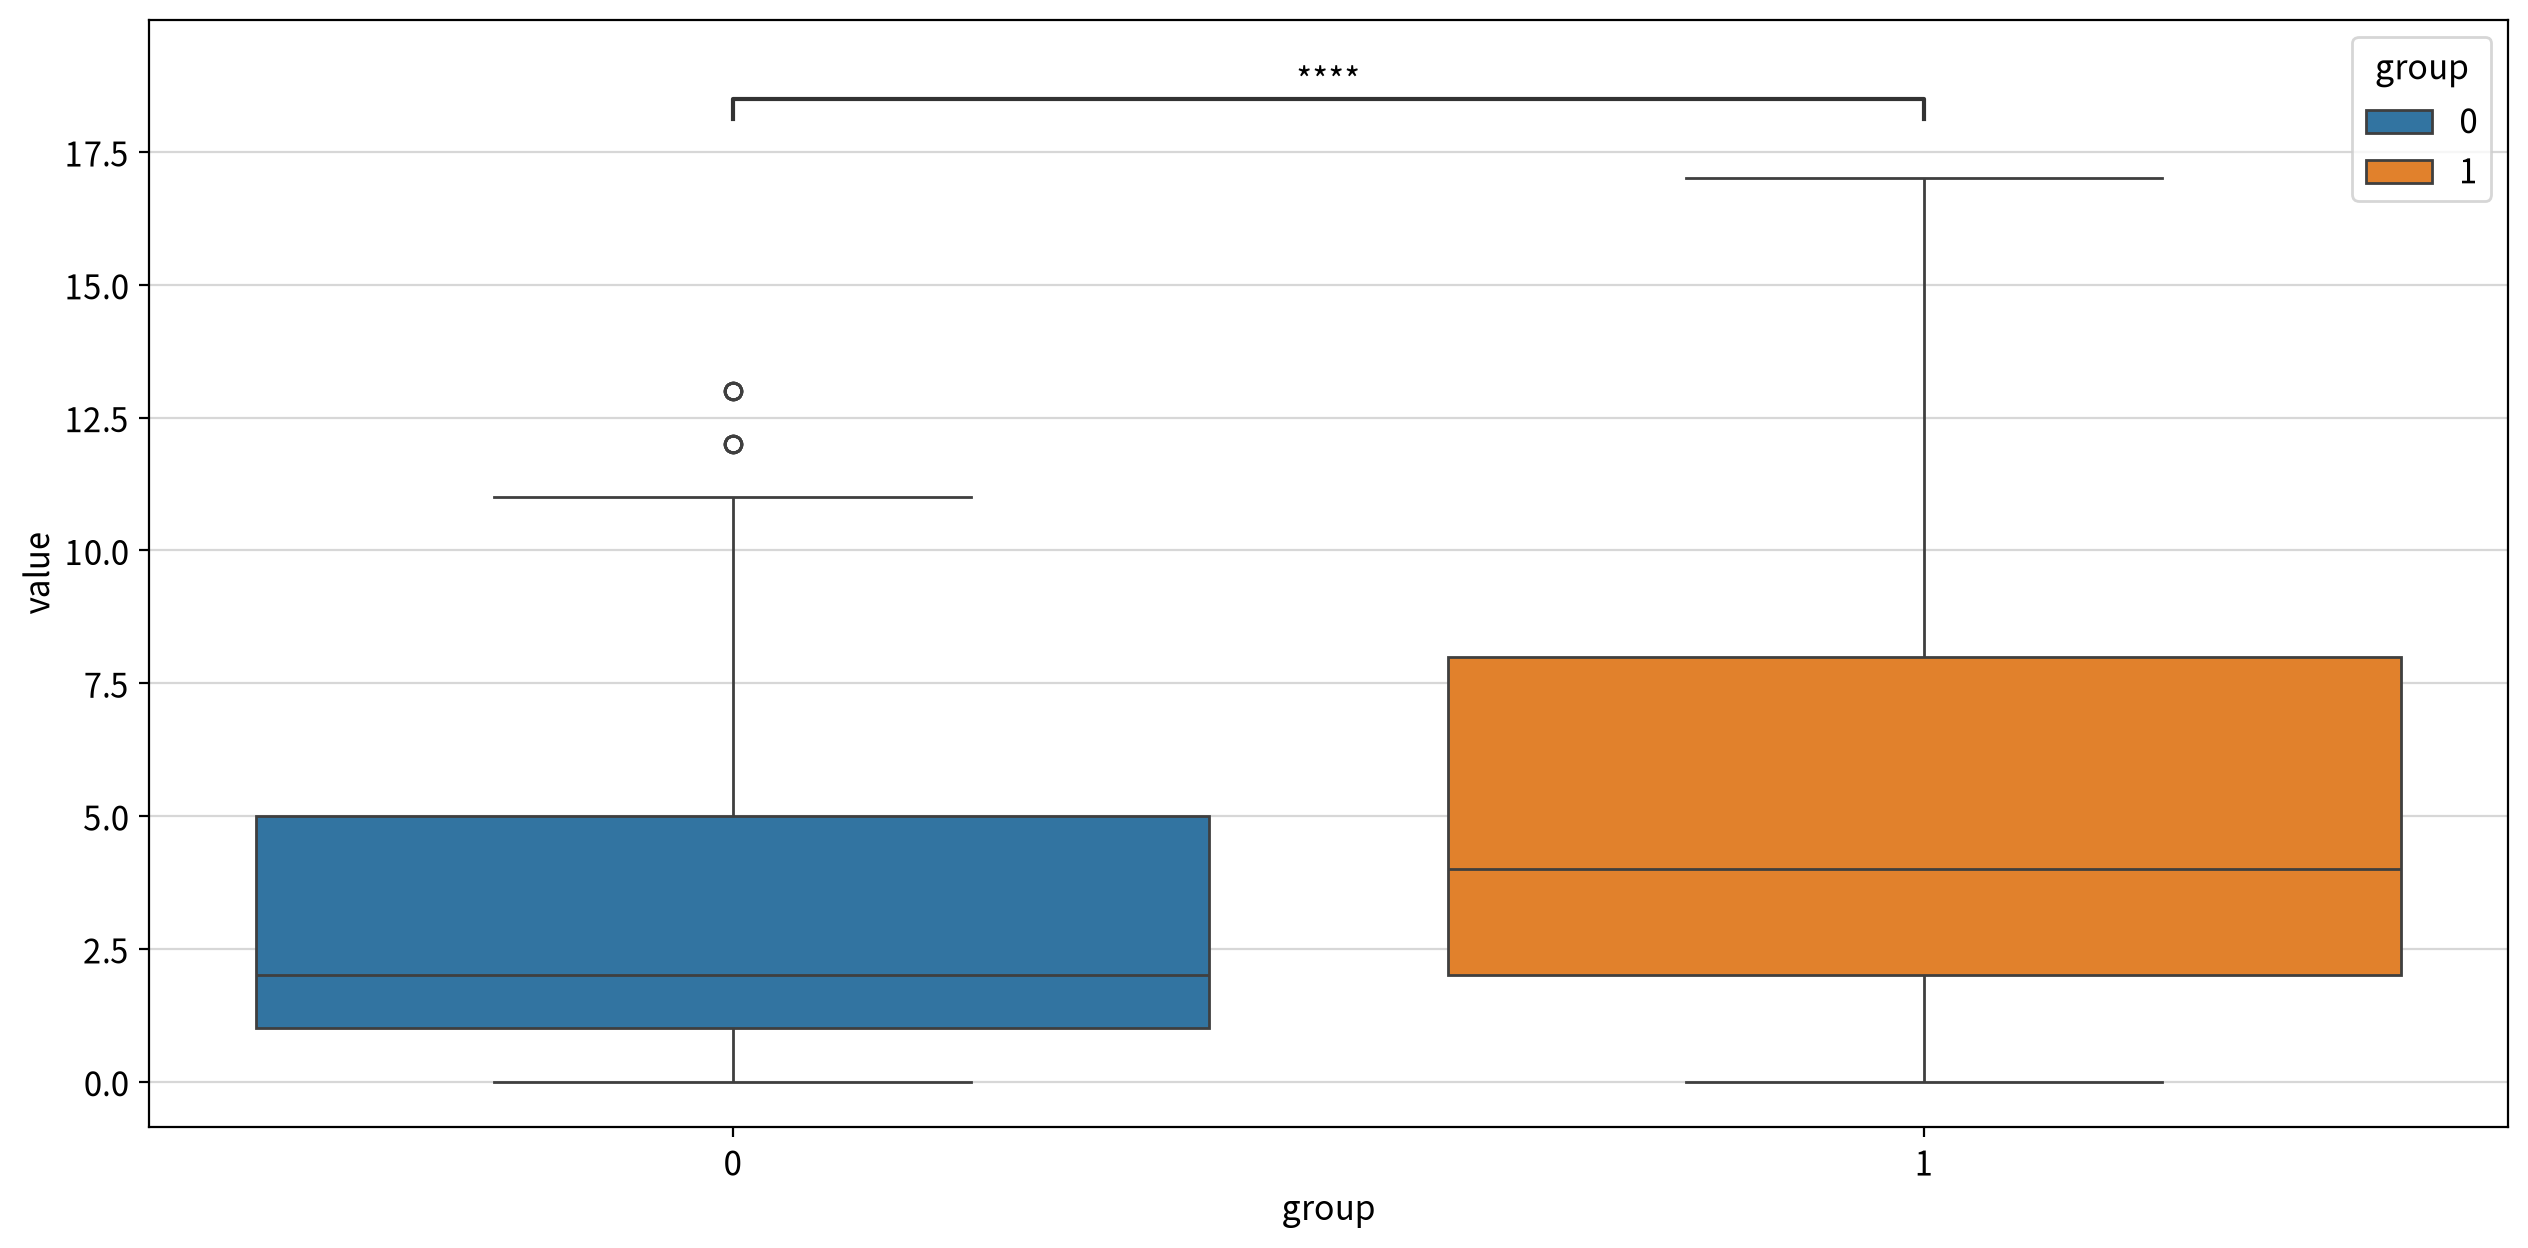

statistic  p-value  significant result
test                alternative                                        
Mann-Whitney U test two-sided   44,489.000    0.000         True  0 ≠ 1
                    less        44,489.000    0.000         True  0 < 1
                    greater     44,489.000    1.000        False  0 ≤ 1

#### ▶︎ Glucose(포도당 부하 검사 수치) → Outcome

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

0 vs. 1: Mann-Whitney-Wilcoxon test two-sided, P_val:2.976e-37 U_stat=2.505e+04


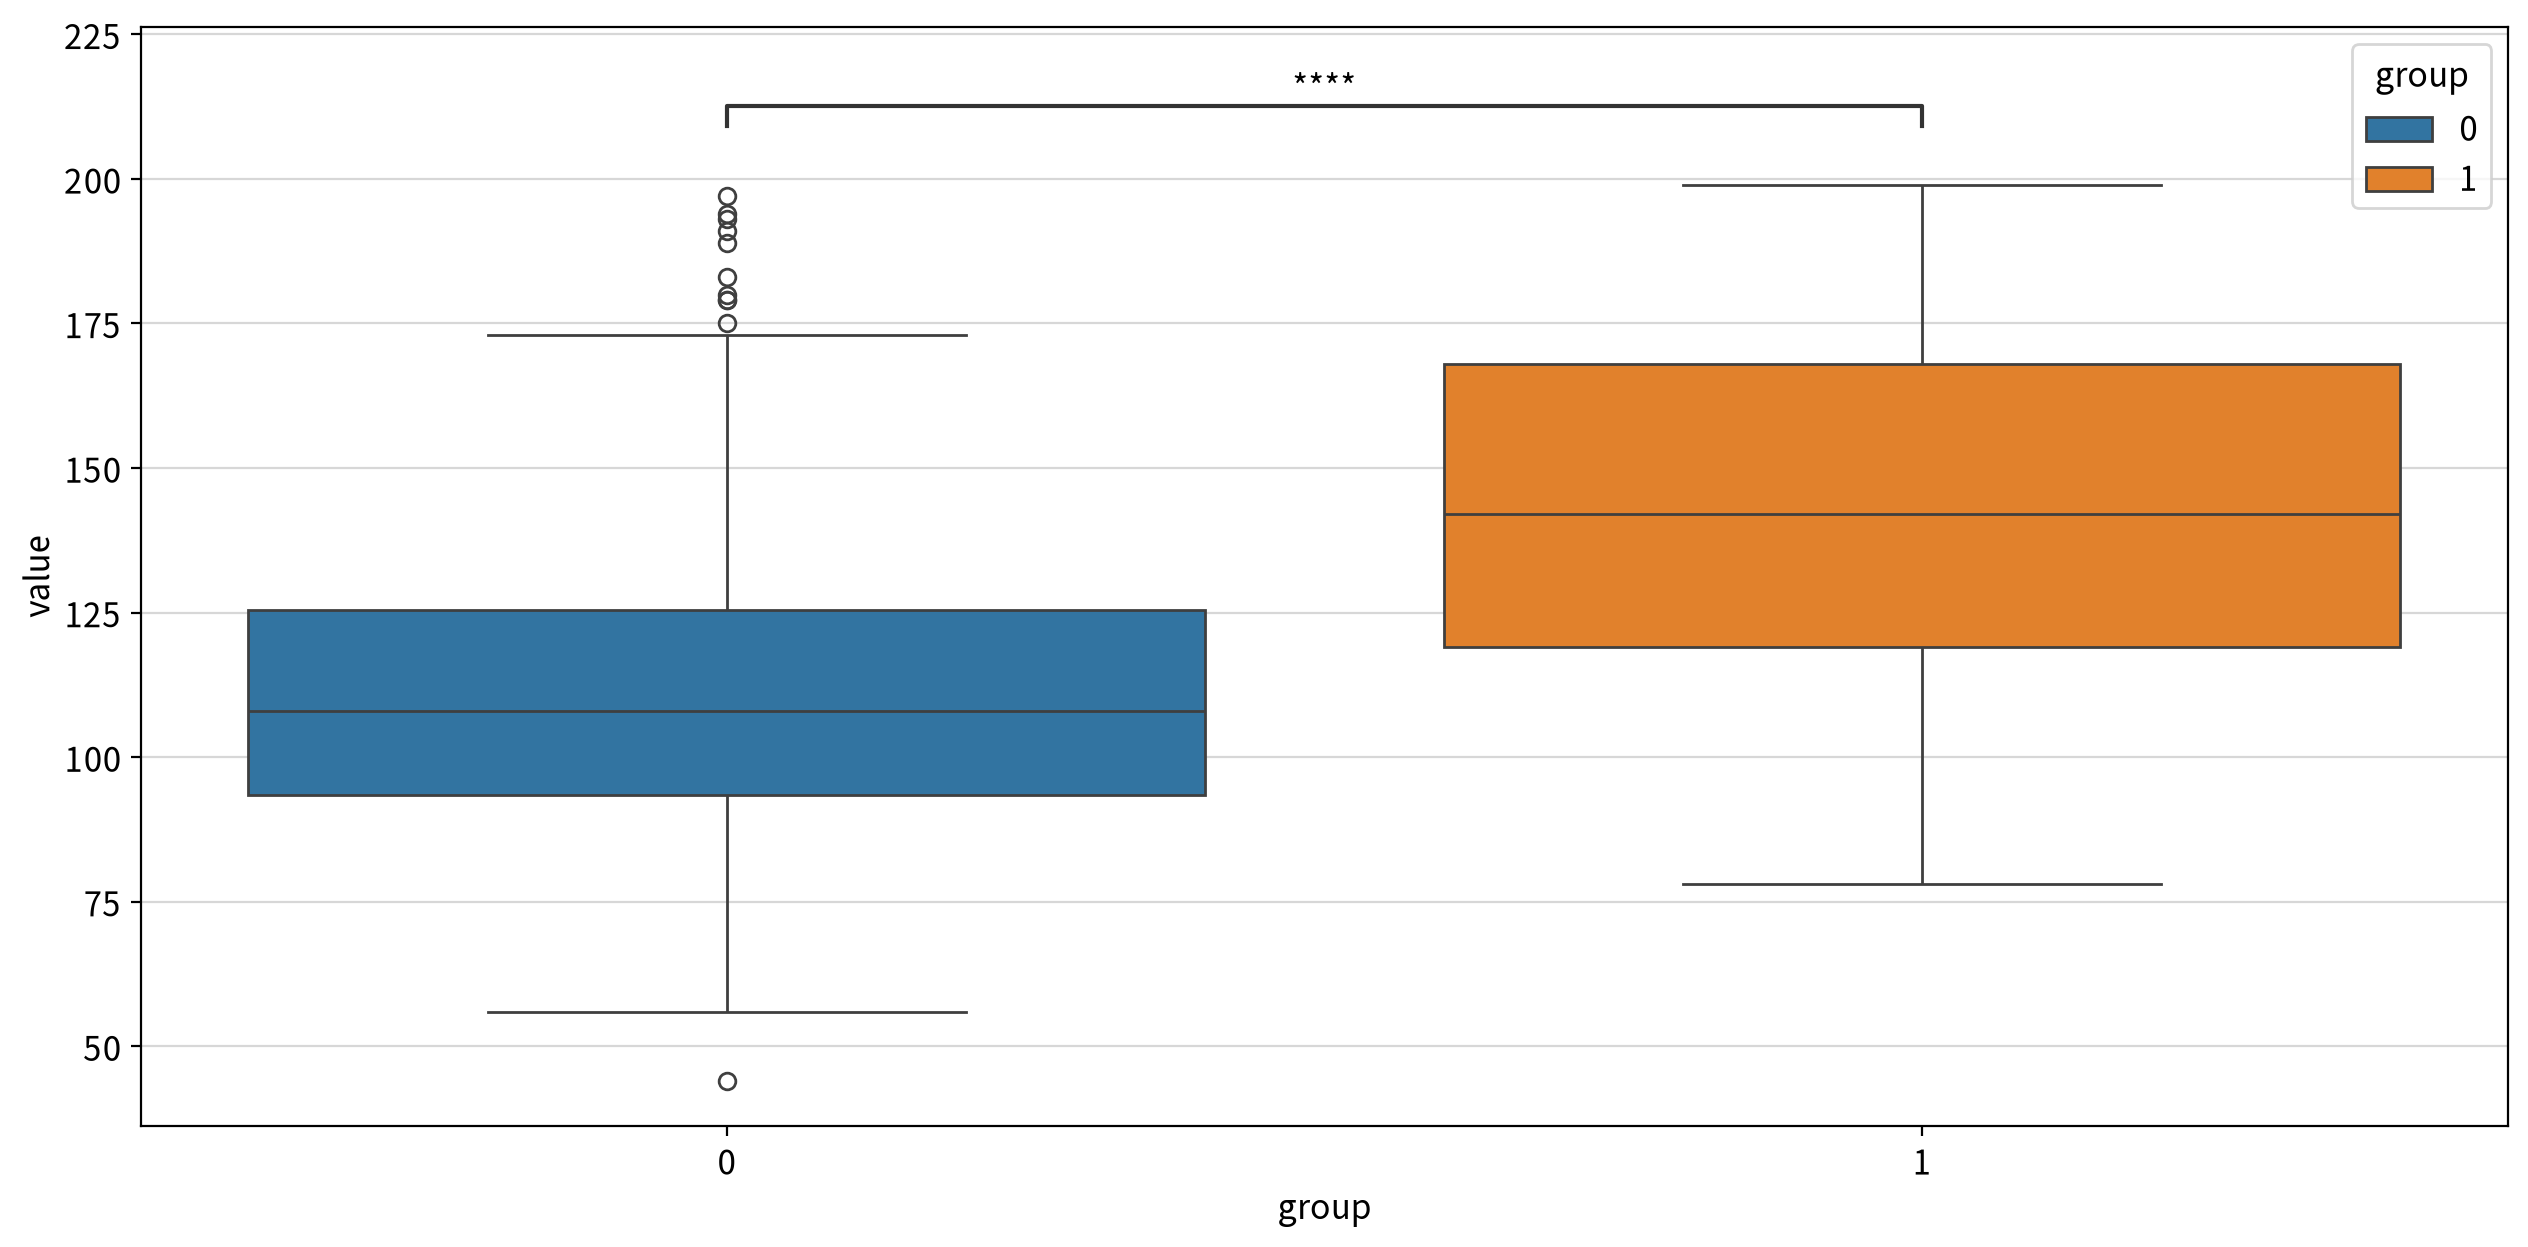

statistic  p-value  significant result
test                alternative                                        
Mann-Whitney U test two-sided   25,047.000    0.000         True  0 ≠ 1
                    less        25,047.000    0.000         True  0 < 1
                    greater     25,047.000    1.000        False  0 ≤ 1

#### ▶︎ BloodPressure(이완기 혈압(mmHg)) → Outcome

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

0 vs. 1: Mann-Whitney-Wilcoxon test two-sided, P_val:2.876e-06 U_stat=4.664e+04


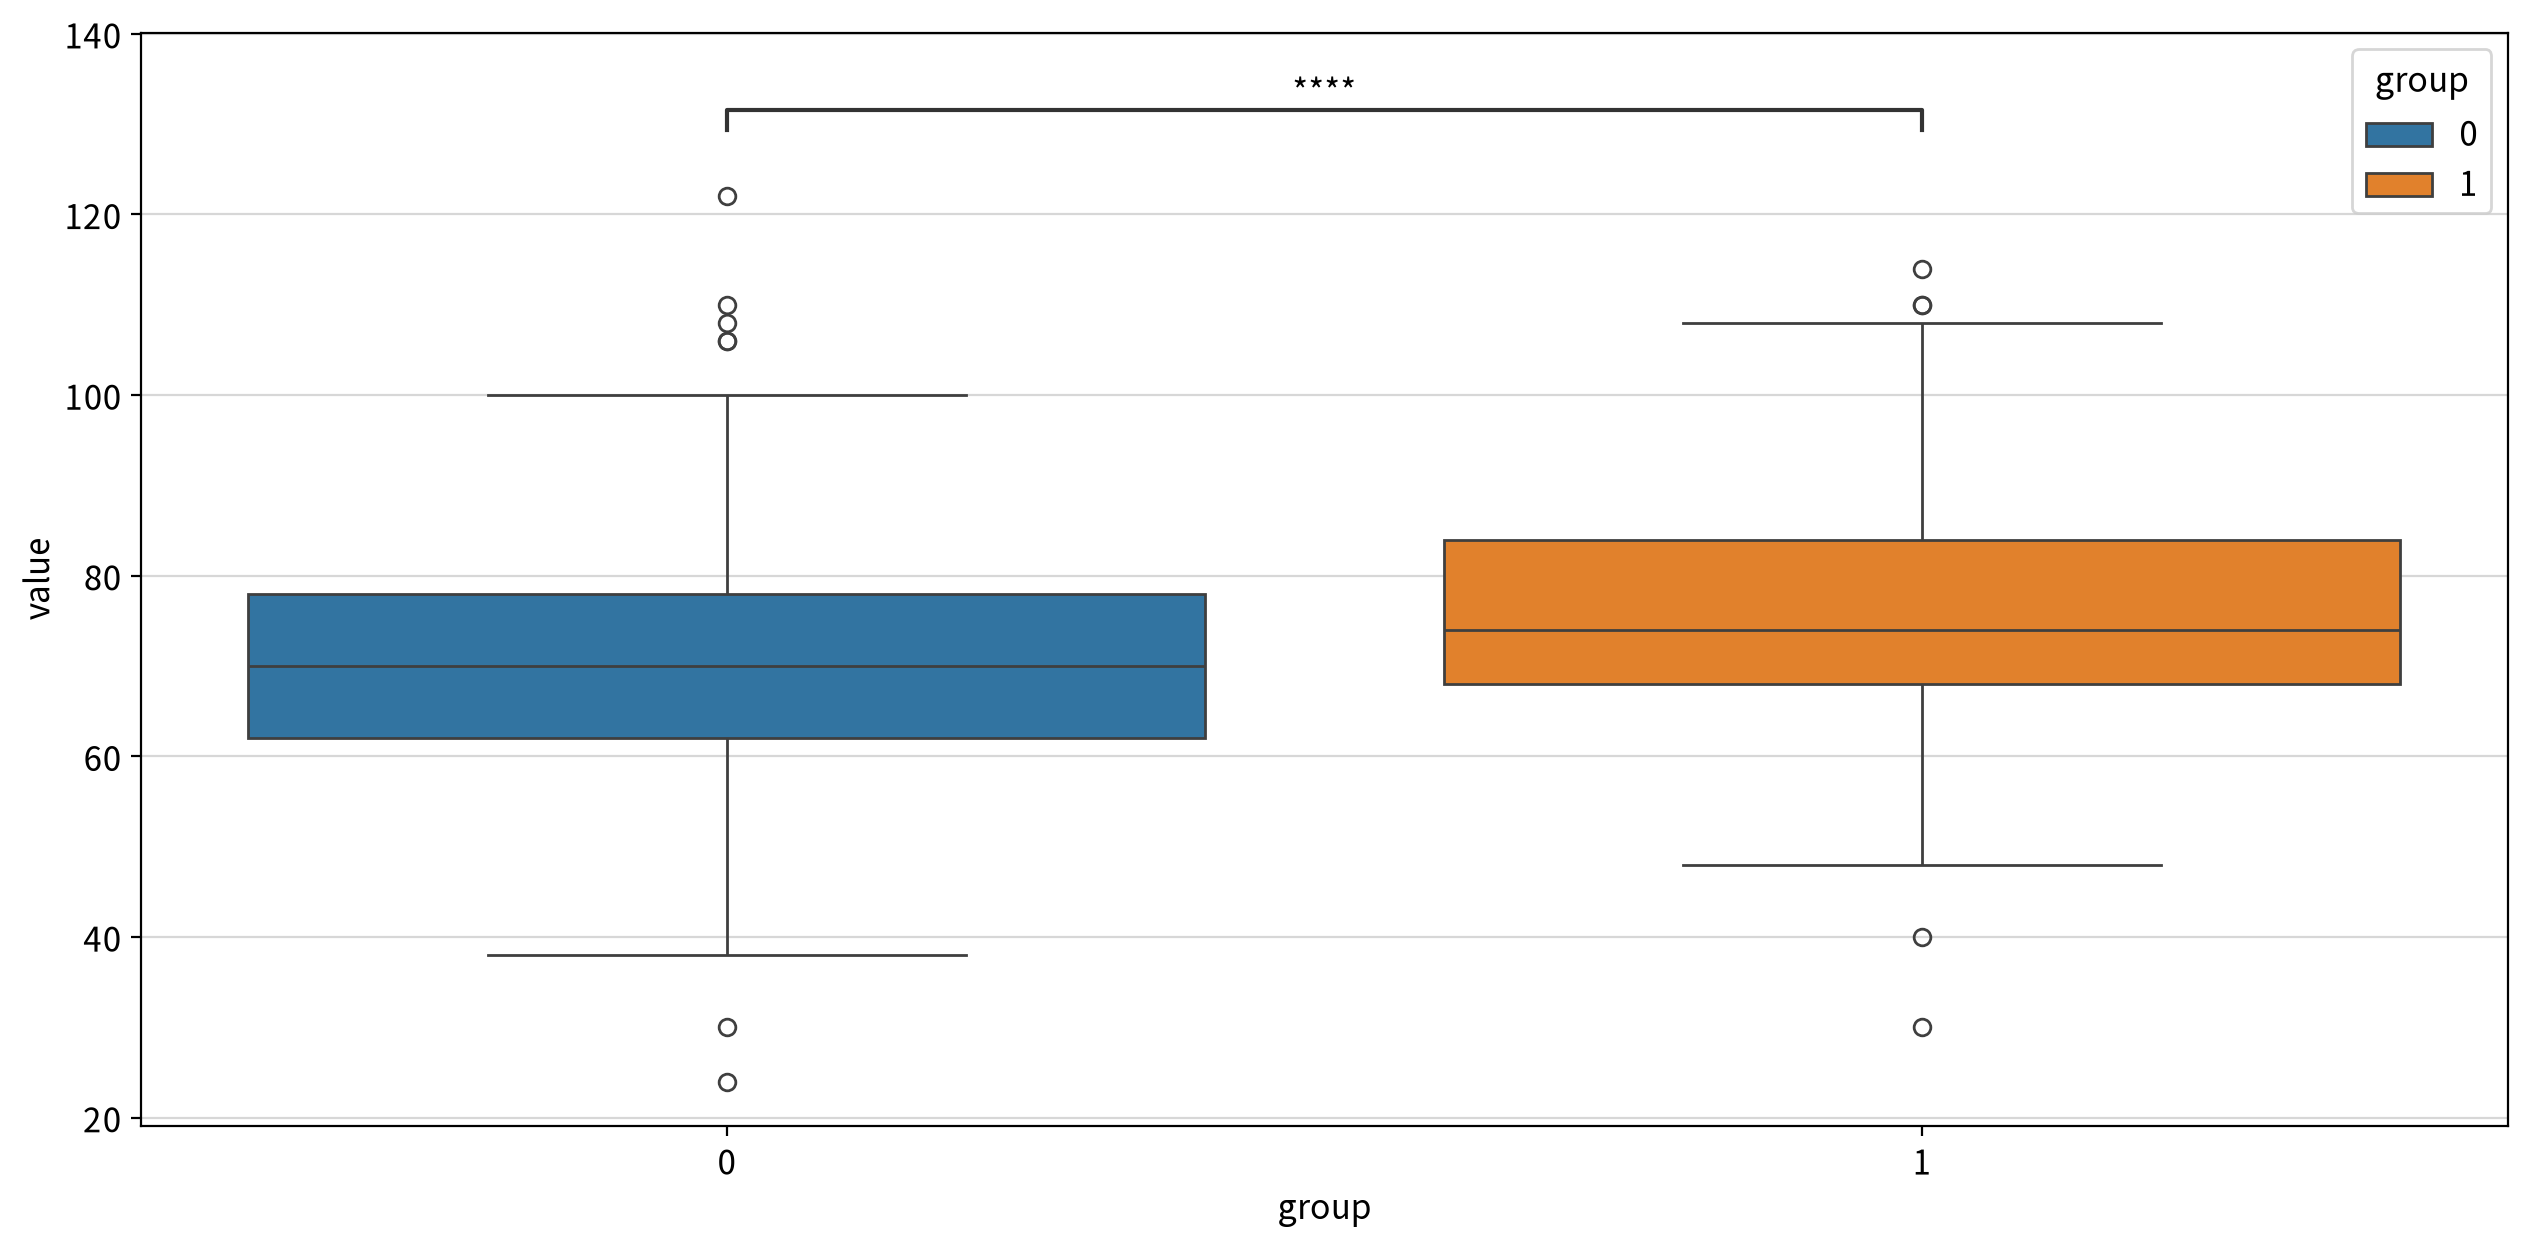

statistic  p-value  significant result
test                alternative                                        
Mann-Whitney U test two-sided   46,644.000    0.000         True  0 ≠ 1
                    less        46,644.000    0.000         True  0 < 1
                    greater     46,644.000    1.000        False  0 ≤ 1

#### ▶︎ BMI(체질량지수) → Outcome

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

0 vs. 1: Mann-Whitney-Wilcoxon test two-sided, P_val:2.064e-15 U_stat=3.792e+04


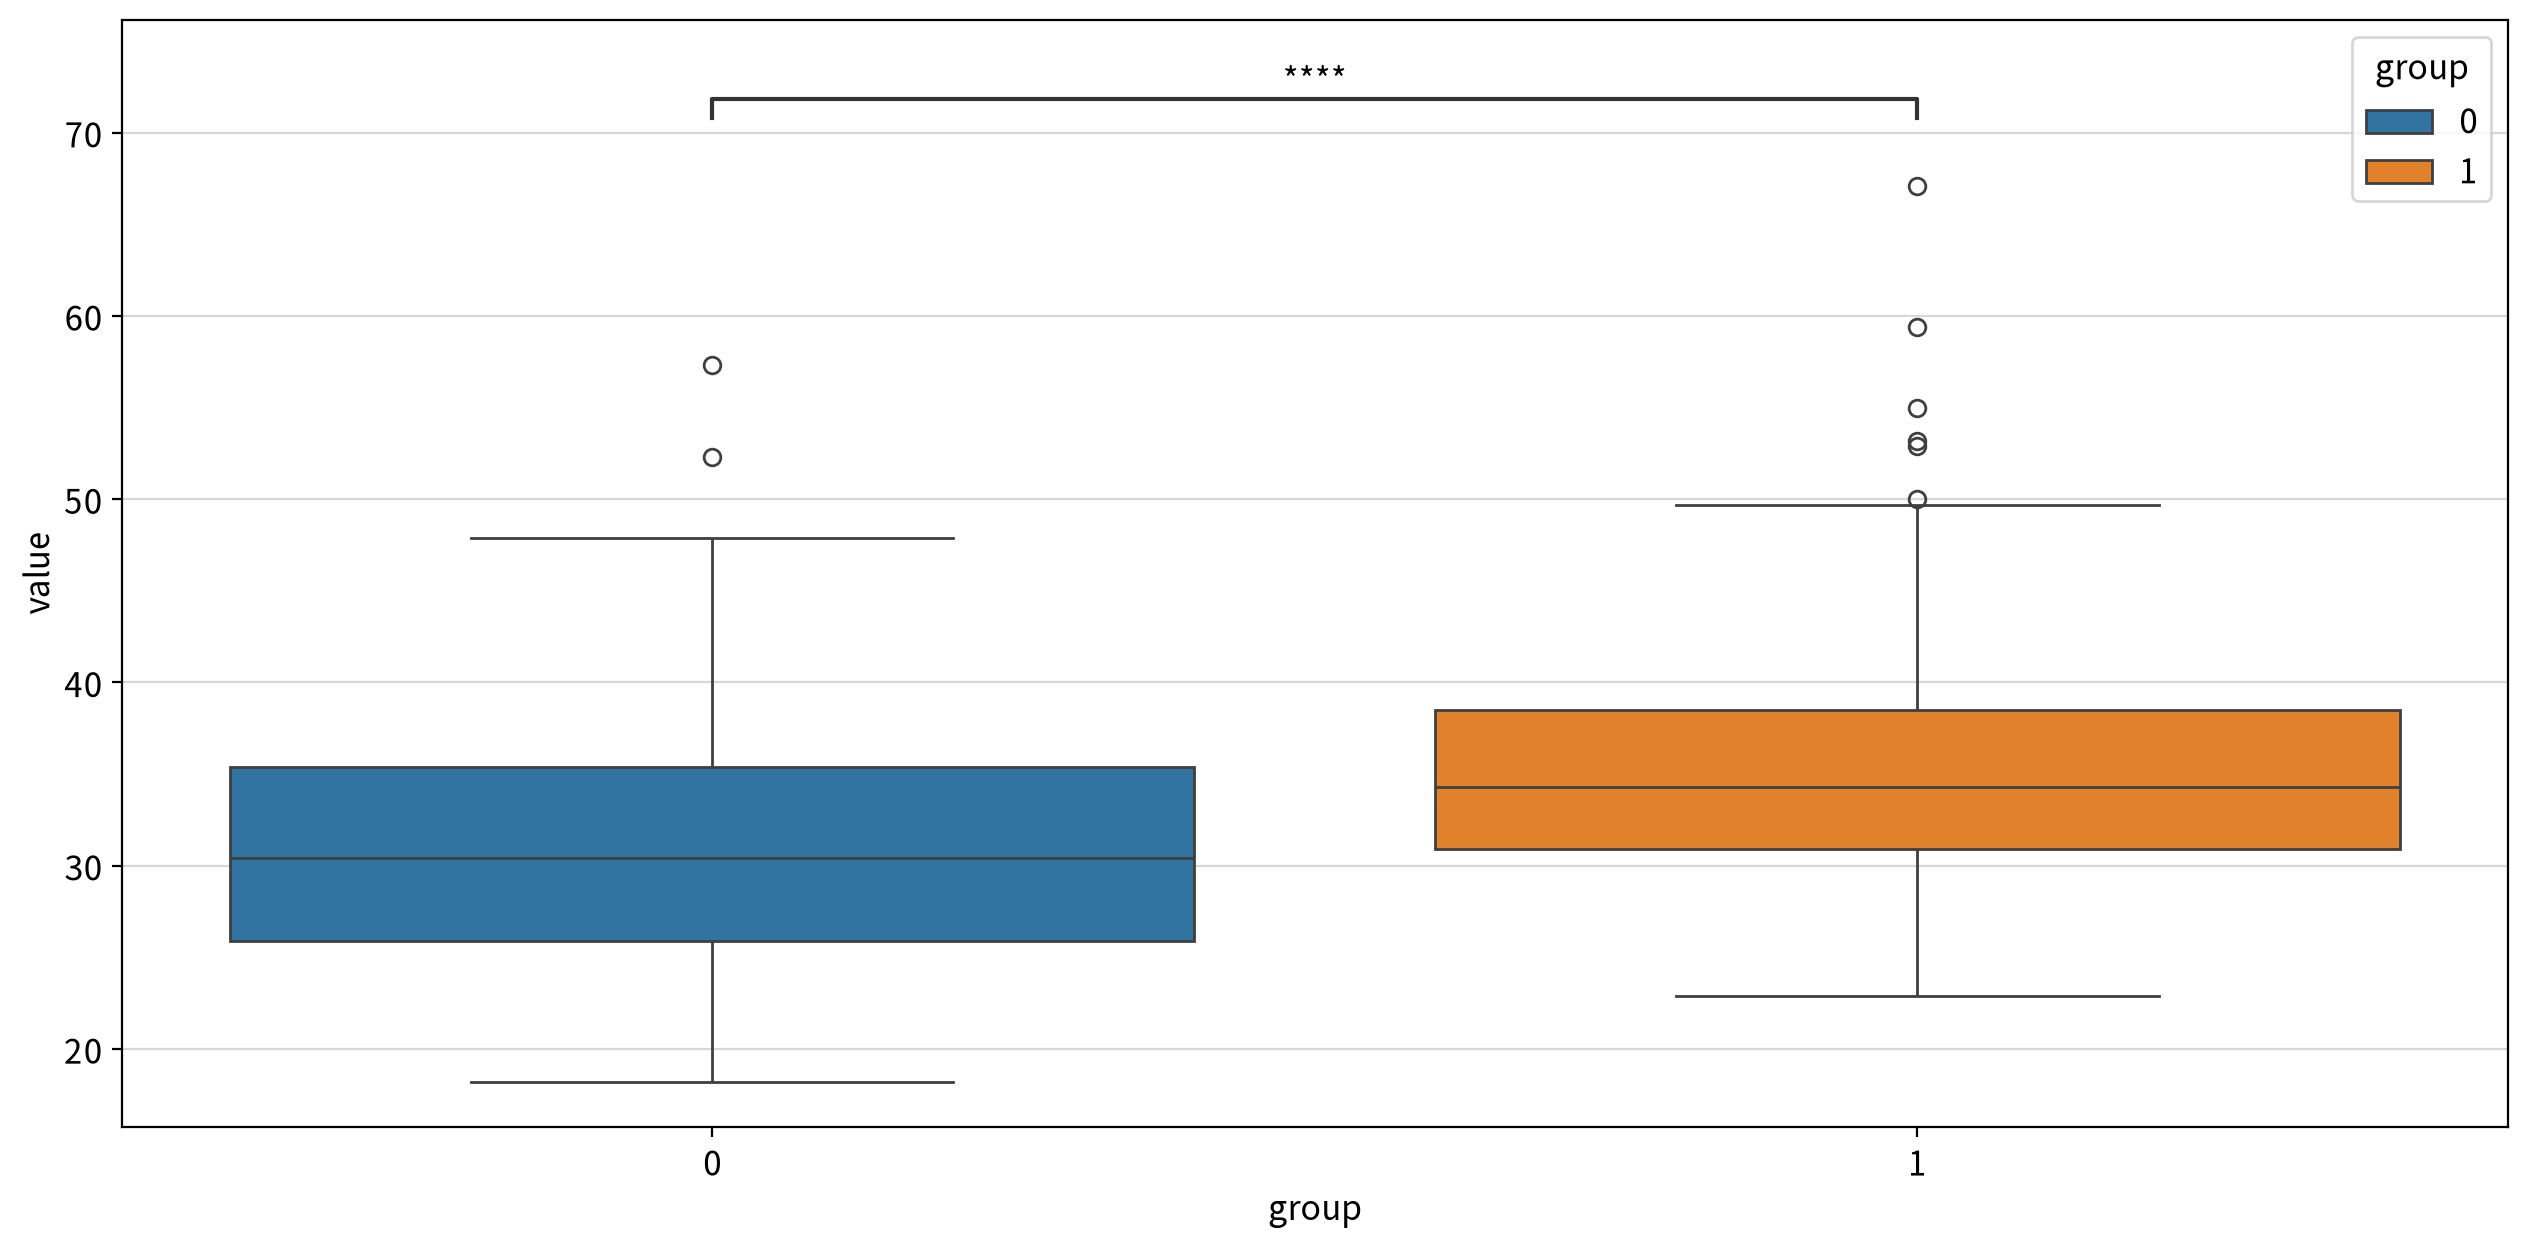

statistic  p-value  significant result
test                alternative                                        
Mann-Whitney U test two-sided   37,919.500    0.000         True  0 ≠ 1
                    less        37,919.500    0.000         True  0 < 1
                    greater     37,919.500    1.000        False  0 ≤ 1

#### ▶︎ DiabetesPedigreeFunction(당뇨 가족력 지수) → Outcome

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

0 vs. 1: Mann-Whitney-Wilcoxon test two-sided, P_val:9.519e-07 U_stat=4.604e+04


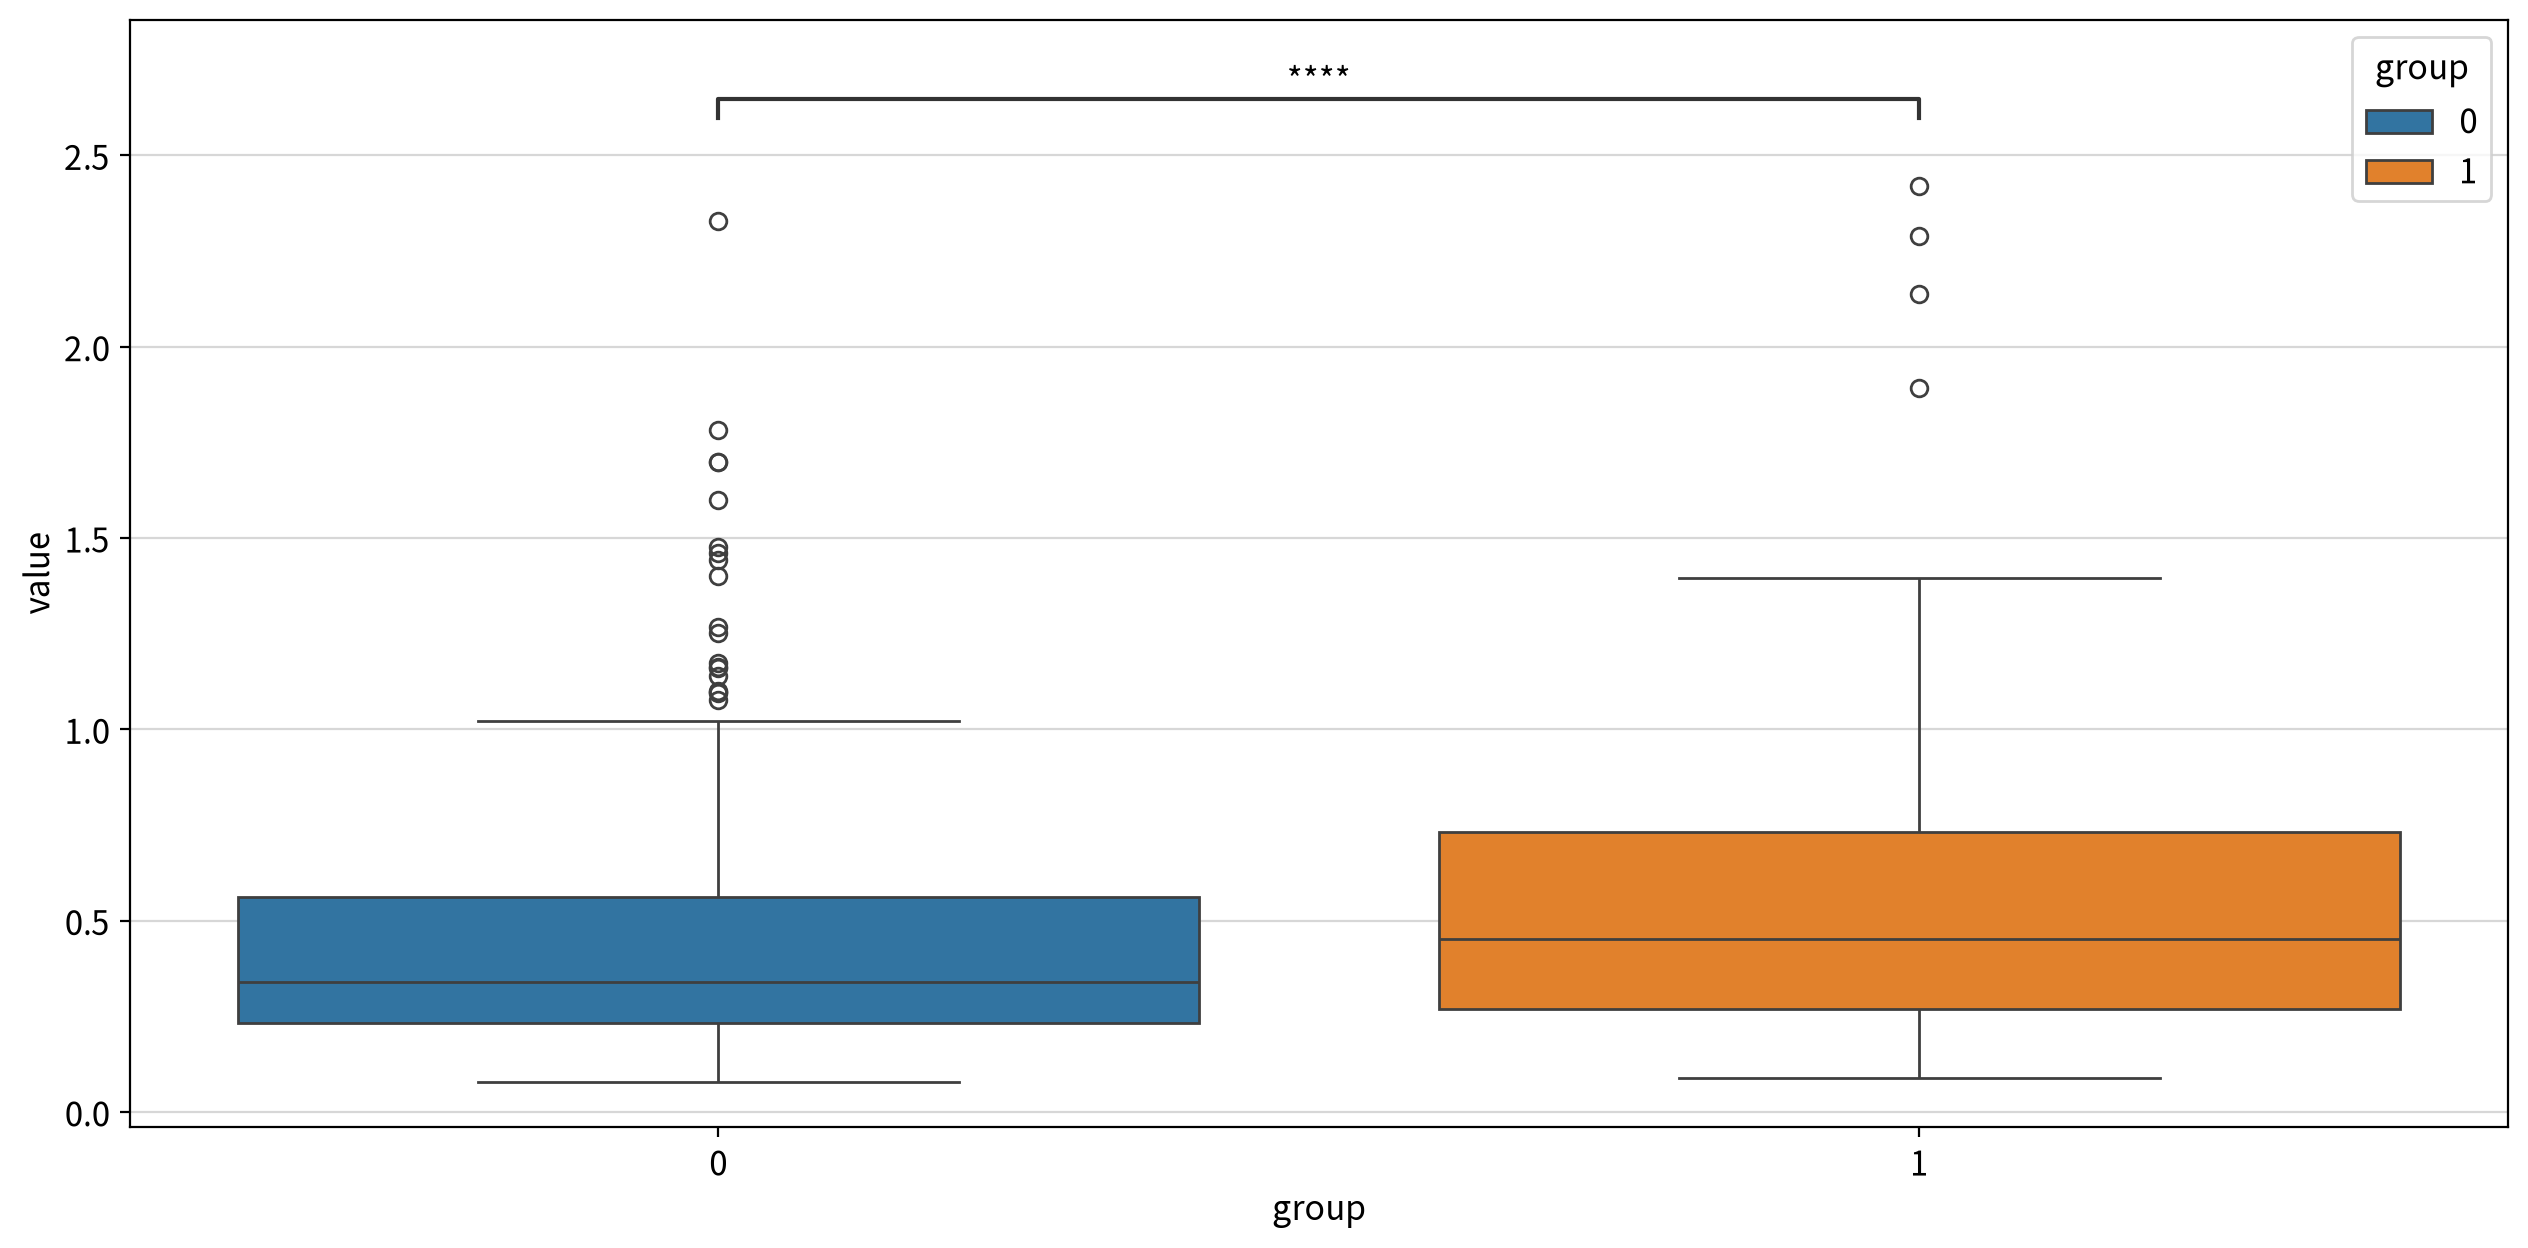

statistic  p-value  significant result
test                alternative                                        
Mann-Whitney U test two-sided   46,035.000    0.000         True  0 ≠ 1
                    less        46,035.000    0.000         True  0 < 1
                    greater     46,035.000    1.000        False  0 ≤ 1

#### ▶︎ Age(나이) → Outcome

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

0 vs. 1: Mann-Whitney-Wilcoxon test two-sided, P_val:1.375e-16 U_stat=3.706e+04


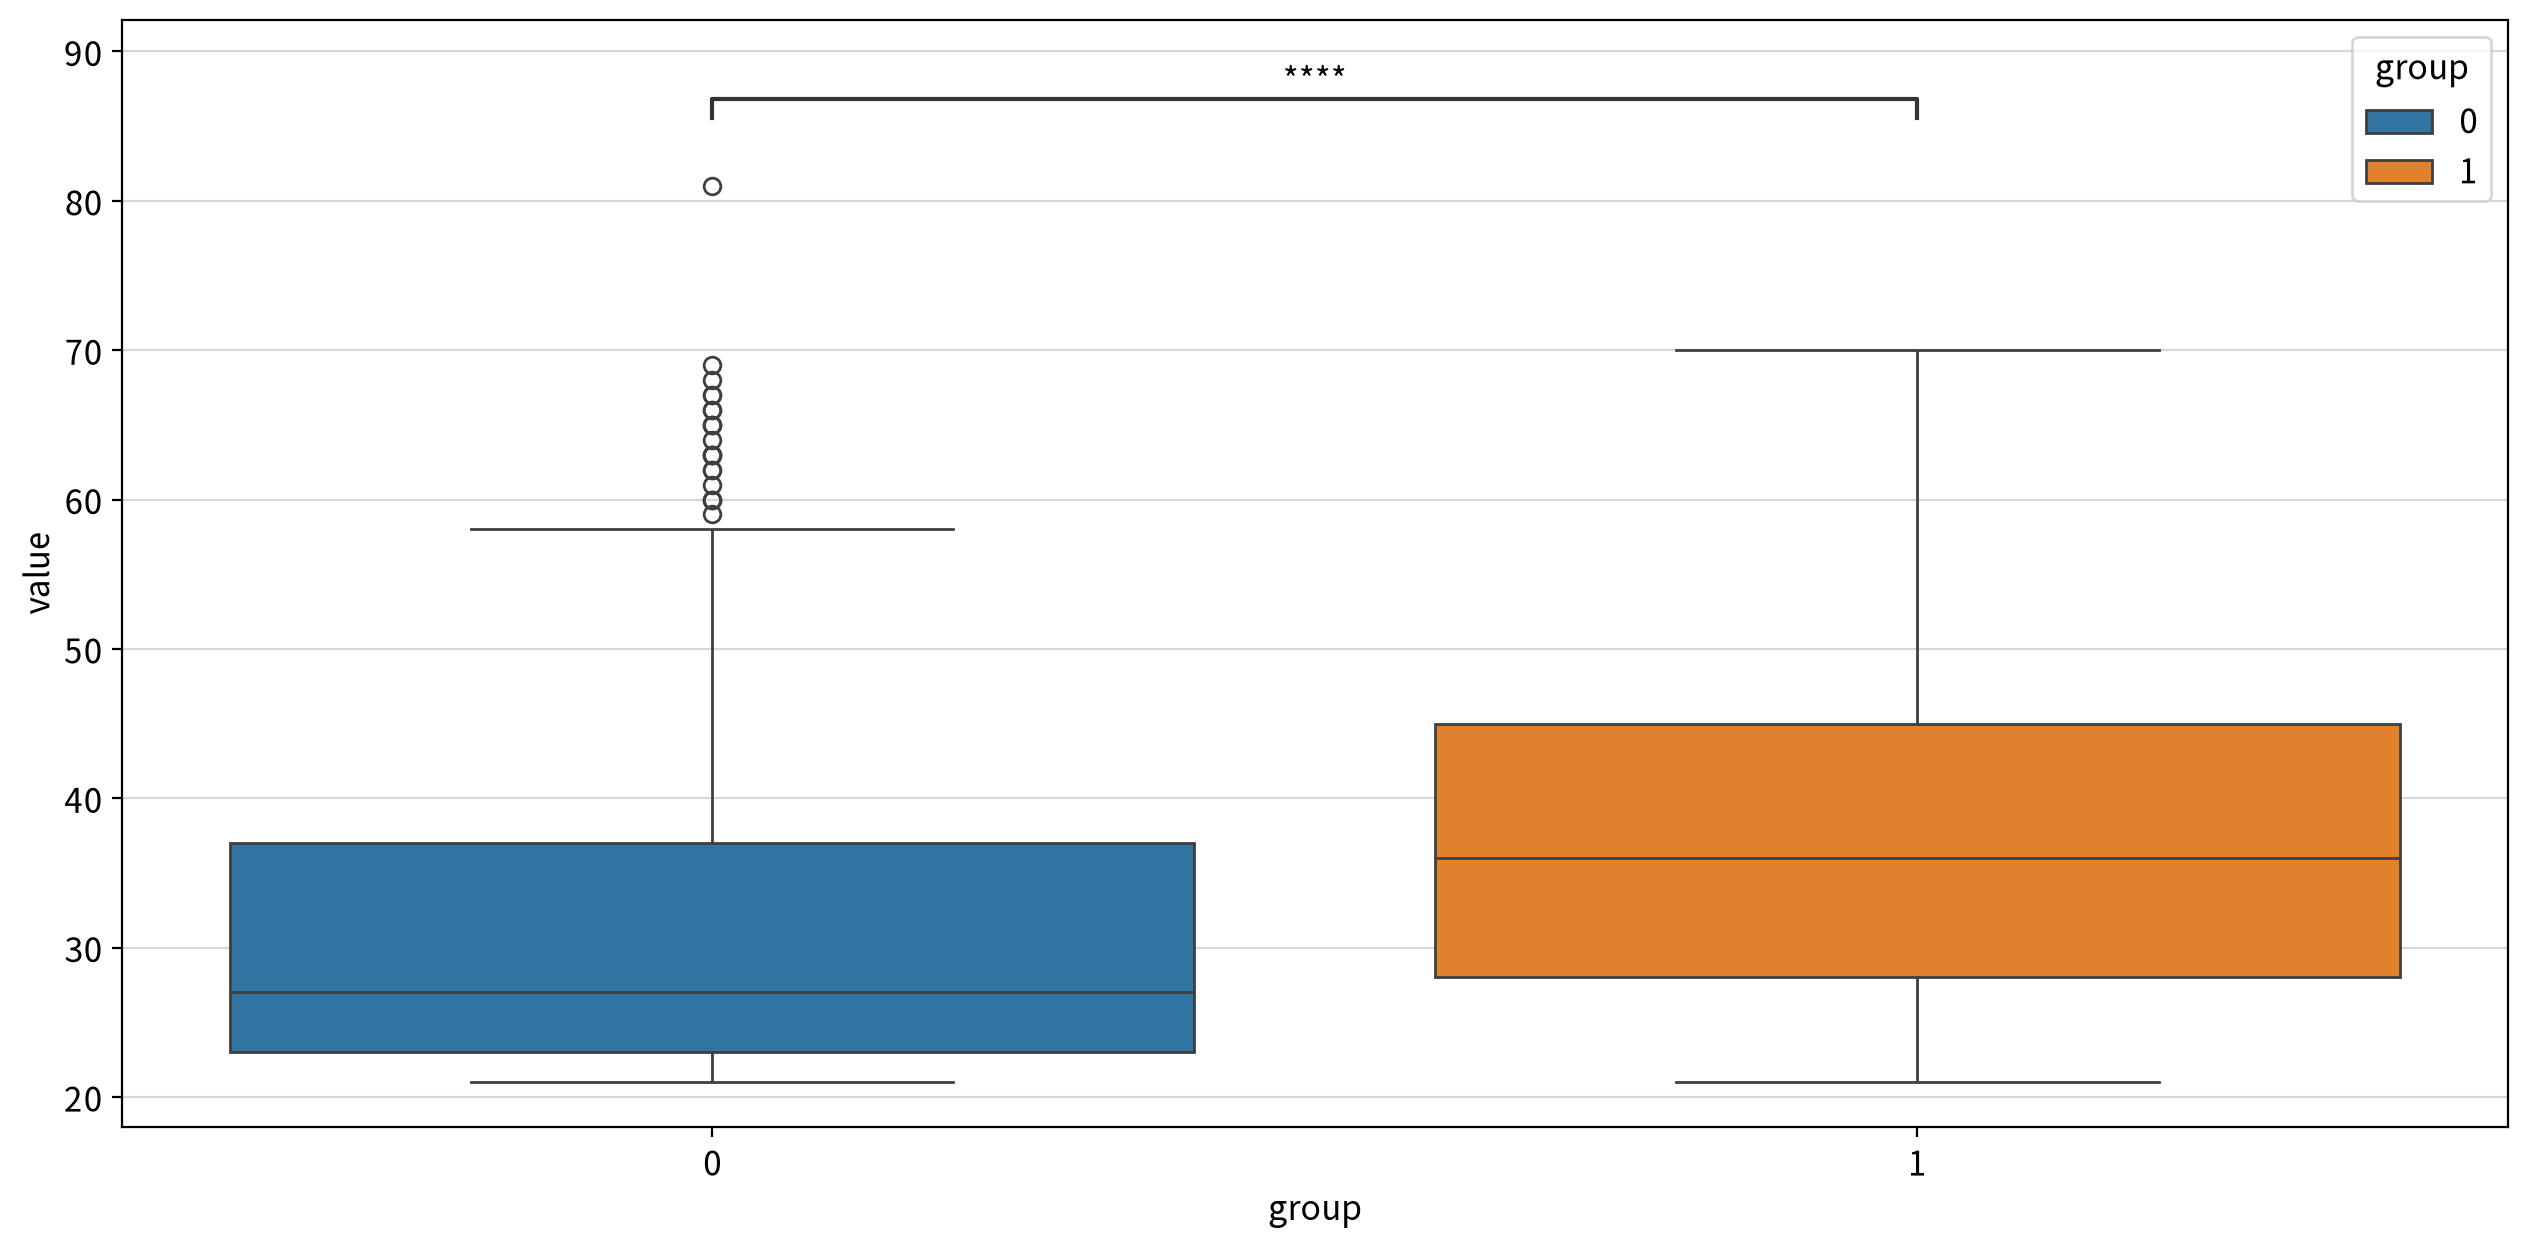

statistic  p-value  significant result
test                alternative                                        
Mann-Whitney U test two-sided   37,064.500    0.000         True  0 ≠ 1
                    less        37,064.500    0.000         True  0 < 1
                    greater     37,064.500    1.000        False  0 ≤ 1

In [75]:
for f in continuous_cols:
    # 빈 줄 출력용
    print()

    # 분석 단위 제목 출력
    display(Markdown(f"#### ▶︎ {f}({column_means[f]}) → {target}"))

    # 종속변수(Outcome)가 집단 기준이 되므로 hue=target, values=f
    wide_df = my_prep.long2wide(df=df4, hue=target, values=f)
    display(my_stats.test_independent(wide_df, 
                                      group1=wide_df.columns[0], group2=wide_df.columns[1]))

---
##### 💡 인사이트

| 변수 | 검정 방법 | 유의확률 | 방향 | 단독 판정 |
|---|---|---|---|---|
| `Glucose` | Mann-Whitney U | < 0.001 | 정상 < 당뇨 | ✅ 채택 |
| `BMI` | Mann-Whitney U | < 0.001 | 정상 < 당뇨 | ✅ 채택 |
| `Age` | Mann-Whitney U | < 0.001 | 정상 < 당뇨 | ✅ 채택 |
| `Pregnancies` | Mann-Whitney U | < 0.001 | 정상 < 당뇨 | ✅ 채택 |
| `DiabetesPedigreeFunction` | Mann-Whitney U | < 0.001 | 정상 < 당뇨 | ✅ 채택 |
| `BloodPressure` | Mann-Whitney U | < 0.001 | 정상 < 당뇨 | ✅ 채택 |

- 정규성이 깨져 **모든 변수에서 Mann-Whitney U**가 선택됐다.
- **6개 변수 모두 당뇨 집단이 유의하게 높았다.** 혈당 · BMI · 나이 · 임신 횟수 · 가족력 · 혈압이 모두 당뇨와 관련이 있다.
- 다만 이는 **하나씩 따로 비교한 결과**다. 나이가 많으면 임신 횟수도 많고 혈압도 높은 것처럼, 변수끼리 얽혀 있으면 다른 변수를 통제했을 때 효과가 사라질 수 있다. → 모델에서 다시 판정한다.

---

## 2-3. 다변량 분석 — 독립변수끼리 중복되는가?

- 독립변수끼리는 종속변수가 명목형이어도 상관분석을 그대로 쓸 수 있다. 목적은 **다중공선성 점검**이다.

In [76]:
corr = my_stats.multi_correlation(data=df4, columns=continuous_cols, plot=False)
my_stats.correlation_summary(corr)

,Pregnancies,Glucose,BloodPressure,BMI,DiabetesPedigreeFunction,Age
Pregnancies,1.000,0.138,0.190,-0.002,-0.037,0.617
Glucose,0.138,1.000,0.249,0.214,0.086,0.274
BloodPressure,0.190,0.249,1.000,0.298,0.009,0.367
BMI,-0.002,0.214,0.298,1.000,0.129,0.110
DiabetesPedigreeFunction,-0.037,0.086,0.009,0.129,1.000,0.028
Age,0.617,0.274,0.367,0.110,0.028,1.000


,max-y,max-coef,count,columns
x,,,,
Age,Pregnancies,0.617,0,-
Pregnancies,Age,0.617,0,-
BloodPressure,Age,0.367,0,-
BMI,BloodPressure,0.298,0,-
Glucose,Age,0.274,0,-
DiabetesPedigreeFunction,BMI,0.129,0,-


---
##### 💡 인사이트

- 강한 상관(|r| ≥ 0.7) 조합은 **하나도 없다.** → 다중공선성 문제 없음.
- 가장 강한 쌍은 **`Age` ↔ `Pregnancies`(r = 0.617)** 다. 나이가 많을수록 임신 횟수도 많은, 당연한 관계다.
  - 강한 수준은 아니지만, 두 변수가 **같은 정보(나이 듦)** 를 일부 나눠 갖고 있다. 모델에서 둘 중 하나의 효과가 다른 쪽에 흡수될 수 있다.

---

## 2-4. 최종 변수 선택

| 채택여부 | 변수 | 검정방법 | 유의확률 | 방향 | 공선성 신호 | 근거 |
|---|---|---|---|---|---|---|
| ✅ 채택 | `Glucose` | Mann-Whitney U | < 0.001 | 정상 < 당뇨 | 없음 | 집단 차이 유의 |
| ✅ 채택 | `BMI` | Mann-Whitney U | < 0.001 | 정상 < 당뇨 | 없음 | 집단 차이 유의 |
| ✅ 채택 | `Age` | Mann-Whitney U | < 0.001 | 정상 < 당뇨 | `Pregnancies`와 중간 상관 (0.617) | 집단 차이 유의 |
| ✅ 채택 | `Pregnancies` | Mann-Whitney U | < 0.001 | 정상 < 당뇨 | `Age`와 중간 상관 (0.617) | 집단 차이 유의 |
| ✅ 채택 | `DiabetesPedigreeFunction` | Mann-Whitney U | < 0.001 | 정상 < 당뇨 | 없음 | 집단 차이 유의 |
| ✅ 채택 | `BloodPressure` | Mann-Whitney U | < 0.001 | 정상 < 당뇨 | 없음 | 집단 차이 유의 |
| ❌ 제외 | `SkinThickness` · `Insulin` | — | — | — | — | 결측 29.6% · 48.7% (PART 1에서 제거) |

- 6개 변수를 모두 모델에 투입하고, **가정 검정 → 후진소거** 순서로 최종 판정한다.

---
# PART 3. 기준선 모형과 가정 검정

## 3-1. 기준선 모형

### (1) 종속변수 라벨링

- 로지스틱 회귀의 종속변수는 **0 / 1 정수**여야 한다. → `정상 = 0`, `당뇨 = 1`
- 즉 이 모형이 예측하는 것은 **P(Outcome = 1) = 당뇨일 확률**이고, 오즈비는 모두 **'당뇨일 오즈'** 에 대한 값이다.

In [77]:
df5 = my_prep.labeling(df=df4, columns=[target])
df5.head()

Outcome (2종): 0=0, 1=1


,Pregnancies,Glucose,BloodPressure,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148.000,72.000,33.600,0.627,50,1
1,1,85.000,66.000,26.600,0.351,31,0
2,8,183.000,64.000,23.300,0.672,32,1
3,1,89.000,66.000,28.100,0.167,21,0
4,0,137.000,40.000,43.100,2.288,33,1


### (2) 기준선 모형 적합

- 모든 변수를 넣은 모형이다. **가정 검정은 변수를 지우기 전의 이 모형**에 대해 수행한다.

In [78]:
fit = my_logit.fit_model(data=df5, y=target)
my_logit.report_variables(fit=fit, data=df5)

,종속변수,독립변수,B,β,표준오차,z,유의확률,B 95% 하한,B 95% 상한,오즈비(OR),OR 95% 하한,OR 95% 상한,공차,VIF
0,Outcome,DiabetesPedigreeFunction,0.961,0.319,0.306,3.135,0.002,0.360,1.561,2.613,1.433,4.764,0.959,1.043
1,Outcome,Pregnancies,0.118,0.396,0.033,3.527,0.000,0.052,0.183,1.125,1.054,1.201,0.687,1.455
2,Outcome,BMI,0.091,0.626,0.016,5.777,0.000,0.060,0.122,1.095,1.062,1.130,0.860,1.162
3,Outcome,Glucose,0.035,1.082,0.004,9.763,0.000,0.028,0.042,1.036,1.029,1.043,0.865,1.156
4,Outcome,Age,0.017,0.199,0.010,1.723,0.085,-0.002,0.036,1.017,0.998,1.037,0.615,1.626
5,Outcome,BloodPressure,-0.009,-0.110,0.009,-1.035,0.301,-0.026,0.008,0.991,0.975,1.008,0.804,1.243


---
##### 💡 인사이트 — 기준선 모형

| 변수 | 단독 비교 (EDA) | 기준선 모형 (다른 변수 통제) | β |
|---|---|---|---|
| `Glucose` | p < 0.001 | z = 9.76, p < 0.001 | **1.082** |
| `BMI` | p < 0.001 | z = 5.78, p < 0.001 | 0.626 |
| `Pregnancies` | p < 0.001 | z = 3.53, p < 0.001 | 0.396 |
| `DiabetesPedigreeFunction` | p < 0.001 | z = 3.13, p = 0.002 | 0.319 |
| **`Age`** | **p < 0.001** | **z = 1.72, p = 0.085** | 0.199 |
| `BloodPressure` | p < 0.001 | z = −1.03, p = 0.301 | −0.110 |

- EDA에서 모두 유의했던 6개 중, **`Age`와 `BloodPressure`가 다른 변수를 통제하자 유의하지 않게** 됐다.
- 그런데 **'나이는 당뇨와 관계없다'는 결과는 의학적 상식과 어긋난다.** 나이와 당뇨의 관계가 직선이 아니라면, 직선만 표현하는 이 모형이 나이의 효과를 제대로 잡지 못한 것일 수 있다.
- 그래서 여기서 바로 변수를 지우지 않고, **가정 검정(로짓 선형성)부터 수행한다.**

---

## 3-2. 가정 검정 — 로짓 선형성

### (1) 기준선 모형의 로짓 선형성 검정 (Box-Tidwell)

- 로지스틱 회귀는 확률이 아니라 **로짓(로그 오즈)과 독립변수가 직선 관계**라고 가정한다.
- 독립변수 x에 `x × ln(x)` 보조항을 넣었을 때 **그 항이 유의하면(p < 0.05) 직선이 아니다.**

In [79]:
my_logit.test_linear(fit=fit, data=df5)

,z,p-value,linearity,위치이동,result
독립변수,,,,,
Pregnancies,0.020,0.984,True,True,귀무가설 채택 → 로짓 선형성 위배 근거 없음
Glucose,-1.084,0.278,True,False,귀무가설 채택 → 로짓 선형성 위배 근거 없음
BloodPressure,-0.564,0.573,True,False,귀무가설 채택 → 로짓 선형성 위배 근거 없음
BMI,-2.224,0.026,False,False,대립가설 채택 → 로짓 선형성 위배 (변환 필요)
DiabetesPedigreeFunction,-2.239,0.025,False,False,대립가설 채택 → 로짓 선형성 위배 (변환 필요)
Age,-4.460,0.000,False,False,대립가설 채택 → 로짓 선형성 위배 (변환 필요)


---
##### 💡 인사이트

- 6개 중 **3개가 위배**다. **`Age`(z = −4.46, p < 0.001)** · `DiabetesPedigreeFunction`(p = 0.025) · `BMI`(p = 0.026)
- 기준선 모형에서 유의하지 않았던 **`Age`가 가장 강하게 위배**됐다. 나이와 당뇨의 관계가 직선이 아니라서, 직선 모형에서는 효과가 가려졌을 가능성이 크다.
- → **위배 신호가 가장 강한 `Age`부터 하나씩 처방한다.**

---

### (2) 선형성 위배 처리 — 진단 → 처방 → 검증 → 재진단 루프

- **진단** : 위배 신호(|z|)가 가장 강한 변수 **하나**를 고른다.
- **처방** : 제곱항(중심화 후 제곱)과 로그변환 중 AIC가 낮은 쪽을 적용한다.
- **검증** : 우도비 검정으로 모형이 실제로 좋아졌는지 확인한다.
- **재진단** : 한 변수를 고치면 다른 변수의 진단도 바뀌므로, **처음부터 다시 진단**한다. 위배 변수가 없어질 때까지 반복한다.

In [80]:
fit_fixed = my_logit.fix_linear(data=df5, y=target)

[라운드 1] 위배 3종 → 'Age' 처방 (z = -4.4596)
     → 제곱항 채택 (제곱항 p = 0.0000, 우도비 p = 2.5579e-06, AIC = 666.74)
[라운드 2] 위배 1종 → 'DiabetesPedigreeFunction' 처방 (z = -2.737)
     → 제곱항 채택 (제곱항 p = 0.0031, 우도비 p = 7.2500e-03, AIC = 661.53)
[라운드 3] 위배 변수 없음 → 루프 종료



,변수,처방,제곱항 p,검증 p,AIC,채택
라운드,,,,,,
1,Age,제곱항,0.000,0.000,666.740,True
2,DiabetesPedigreeFunction,제곱항,0.003,0.007,661.530,True


---
##### 💡 인사이트 — 두 번의 처방으로 선형성 충족

| 라운드 | 처방 대상 | 처방 | 우도비 p | AIC |
|---|---|---|---|---|
| 1 | `Age` | 제곱항 | < 0.001 | 666.74 |
| 2 | `DiabetesPedigreeFunction` | 제곱항 | 0.007 | 661.53 |

- **`Age`를 처방하자 `BMI`의 위배가 저절로 해소**됐다(위배 3종 → 1종). 나이를 직선으로 잘못 넣은 탓에, 나이의 곡선 효과가 BMI 진단에까지 번져 있었던 것이다. **한 번에 하나씩 고치고 재진단해야 하는 이유**다.
- 두 처방 모두 우도비 검정에서 **모형을 유의하게 개선**했고(p < 0.05), 처방할 때마다 AIC가 낮아졌다.

---

### (3) 계층 원칙(hierarchy principle)

- 제곱항이 모형에 있으면 **1차항은 유의하지 않아도 남긴다.** 1차항을 빼면 곡선의 꼭짓점이 중심값에 고정돼 곡선 모양이 왜곡되기 때문이다.

### (4) 독립성 검정 — Durbin-Watson

In [81]:
my_logit.test_independent(fit_fixed)

,statistic,independence,result
Durbin-Watson,1.906,True,독립성 만족


---
##### 💡 인사이트

- DW = **1.906**로 기준 범위(1.5 ~ 2.5) 안에 있다. → **독립성 만족.**
- 724명은 서로 다른 사람이고 측정 순서에 의미가 없으므로, 자료 수집 설계로 봐도 독립이 타당하다.

---

### (5) 가정 검정 결과 확정

- 처방 내역(`recipe`)을 확정한다. 이 내역이 다음 단계 파이프라인의 옵션이 된다.

In [82]:
recipe = fit_fixed.recipe_         # 변수별 처방 방식과 기준값

for col, rule in recipe.items():
    print(f"{col:26s} : {rule['method']}")

print("\n처방 제외 (선형성 충족) :", [c for c in continuous_cols if c not in recipe])
print("미해소 :", fit_fixed.unresolved_)

Age                        : square
DiabetesPedigreeFunction   : square

처방 제외 (선형성 충족) : ['Pregnancies', 'Glucose', 'BloodPressure', 'BMI']
미해소 : []


---
# PART 4. 로지스틱 회귀 모델링

### (1) 전처리 체크포인트 정의

- **0~3번은 가정 검정을 반영하지 않은 조합**, **4~7번은 `recipe`(로짓 선형성 처방)를 적용한 조합**이다. 두 계열의 전처리를 똑같이 맞춰 **처방의 순수한 효과**를 본다.
- 공선성 제거(`vif=True`)는 모든 체크포인트에 공통으로 건다(PART 2에서 공선성 문제가 없음을 확인).

In [83]:
checkpoints = {
    # --- 가정 검정 미반영 ---
    "0_기준선":             dict(vif=True),
    "1_후진소거":           dict(backward=True, vif=True),
    "2_이상치대체":         dict(backward=True, outlier=True, vif=True),
    "3_정규화":             dict(backward=True, outlier=True, vif=True, scale=True),

    # --- 가정 검정 반영 (로짓 선형성 처방) ---
    "4_가정반영":           dict(recipe=recipe, vif=True),
    "5_가정반영+후진소거":   dict(recipe=recipe, backward=True, vif=True),
    "6_가정반영+이상치대체": dict(recipe=recipe, backward=True, outlier=True, vif=True),
    "7_가정반영+정규화":     dict(recipe=recipe, backward=True, outlier=True, vif=True, scale=True),
}

### (2) 체크포인트별 모델 적합

In [84]:
fits = {}    # 적합된 모델을 누적할 딕셔너리

for name in checkpoints:
    print(f"\n▶︎ --- {name} ---")
    fits[name] = my_logit.fit_pipeline(data=df5, y=target, columns=continuous_cols,
                                       name=name, **checkpoints[name])

print("\n누적된 모델 :", len(fits), "개")


▶︎ --- 0_기준선 ---

완료! 남은 변수: ['Age', 'BMI', 'BloodPressure', 'DiabetesPedigreeFunction', 'Glucose', 'Pregnancies']
최대 VIF = 1.63


▶︎ --- 1_후진소거 ---

완료! 남은 변수: ['Age', 'BMI', 'BloodPressure', 'DiabetesPedigreeFunction', 'Glucose', 'Pregnancies']
최대 VIF = 1.63

유의하지 않은 독립변수 제거 → BloodPressure (p = 0.3008)
유의하지 않은 독립변수 제거 → Age (p = 0.1284)

▶︎ --- 2_이상치대체 ---

완료! 남은 변수: ['Age', 'BMI', 'BloodPressure', 'DiabetesPedigreeFunction', 'Glucose', 'Pregnancies']
최대 VIF = 1.64

유의하지 않은 독립변수 제거 → BloodPressure (p = 0.3164)
유의하지 않은 독립변수 제거 → Age (p = 0.1064)

▶︎ --- 3_정규화 ---

완료! 남은 변수: ['Age', 'BMI', 'BloodPressure', 'DiabetesPedigreeFunction', 'Glucose', 'Pregnancies']
최대 VIF = 1.64

유의하지 않은 독립변수 제거 → BloodPressure (p = 0.3164)
유의하지 않은 독립변수 제거 → Age (p = 0.1064)

▶︎ --- 4_가정반영 ---

완료! 남은 변수: ['Age_c', 'Age_c2', 'BMI', 'BloodPressure', 'DiabetesPedigreeFunction_c', 'DiabetesPedigreeFunction_c2', 'Glucose', 'Pregnancies']
최대 VIF = 3.57


▶︎ --- 5_가정반영+후진소거 ---

완료! 남은 변수: ['Age_c', 'Age_c2', 

### (3) 모델 성능 비교

- AUC 1순위 모델과 차이가 5% 이내인 모델 중 **변수가 적은 모델**을 우선한다(간명성).

In [85]:
best = my_logit.compare_models(fits)
print("간명성 기준 1순위 :", best.name_)

,변수 수,정확도,정밀도,재현율,F1,AUC,Pseudo R²,AIC,Gap(%)
모델,,,,,,,,,
2_이상치대체,4,0.779,0.726,0.574,0.641,0.842,0.278,683.346,1.720
3_정규화,4,0.779,0.726,0.574,0.641,0.842,0.278,683.346,1.720
1_후진소거,4,0.778,0.725,0.570,0.638,0.841,0.274,686.227,1.760
6_가정반영+이상치대체,5,0.779,0.717,0.590,0.648,0.855,0.301,662.922,0.190
7_가정반영+정규화,5,0.779,0.717,0.590,0.648,0.855,0.301,662.922,0.190
5_가정반영+후진소거,6,0.782,0.722,0.594,0.652,0.854,0.305,661.312,0.210
0_기준선,6,0.776,0.721,0.570,0.637,0.843,0.278,686.861,1.500
4_가정반영,8,0.779,0.717,0.590,0.648,0.856,0.309,661.529,0.000


간명성 기준 1순위 : 2_이상치대체


---
##### 💡 인사이트 — 간명성 규칙이 가정을 위배한 모델을 골랐다

| 계열 | 대표 모델 | 변수 수 | AUC | 정확도 | Pseudo R² | AIC |
|---|---|---|---|---|---|---|
| 가정 검정 미반영 (0~3번) | 2_이상치대체 | 4 | 0.842 | 0.779 | 0.278 | 683.35 |
| **가정 검정 반영 (4~7번)** | **5_가정반영+후진소거** | **6** | **0.854** | **0.782** | **0.305** | **661.31** |

- 로짓 선형성 처방을 반영하자 **AUC 0.842 → 0.854, AIC 683 → 661**로 모든 지표가 좋아졌다.
- 이상치 대체 · 정규화는 어느 계열에서도 성능을 거의 바꾸지 못했다(AUC 차이 0.001 이하). **성능을 바꾼 것은 전처리가 아니라 가정 검정**이었다.
- 그런데 `compare_models()`는 **`2_이상치대체`를 1순위**로 골랐다. AUC 차이가 1.72%로 5% 이내이고 변수가 더 적기 때문이다.
- 하지만 `2_이상치대체`는 **로짓 선형성이 위배된 상태 그대로**이고, 그 결과 **나이가 '유의하지 않다'며 지워진 모델**이다. 가정을 위배한 모델의 계수는 해석할 수 없으므로, 성능이 근소하게 비슷해도 고를 수 없다.

---

### (4) 최종 모델 선택

- 간명성 규칙은 **가정을 충족한 모델(4~7번) 안에서만** 적용한다.
- 4~7번 중 변수가 가장 적은 것은 `6` · `7`번(5개)이지만, 두 모델은 후진소거로 **`DiabetesPedigreeFunction_c2`(제곱항)를 지웠다.** 이 제곱항은 가족력 지수의 로짓 선형성 위배를 고치려고 넣은 처방이라, 지우면 **위배가 되살아난다.**
- 따라서 처방을 모두 유지하면서 변수가 가장 적은 **`5_가정반영+후진소거`(6개)를 최종 채택**한다.
  - `5`번은 처방과 무관한 `Pregnancies`(p = 0.235) · `BloodPressure`(p = 0.125)만 지웠고, 4번보다 변수가 2개 적으면서 AUC 차이는 0.21%다.
  - → **자동 선택 결과는 언제나 분석자가 가정과 원칙에 비춰 검토해야 한다.**

In [86]:
# 가정 검정을 충족한 모델(4~7번) 안에서 간명성 규칙을 적용한다
final_name = "5_가정반영+후진소거"

final_fit = fits[final_name]
final_data = final_fit.data_[["Outcome"] + list(final_fit.model.exog_names[1:])]   # 상수항을 제외하여 최종 모델에 남은 변수만 출력

print("최종 모델 :", final_name)
print("독립변수  :", int(final_fit.df_model), "개")

최종 모델 : 5_가정반영+후진소거
독립변수  : 6 개


---
# PART 5. 최종 모델 보고

### (1) 모형 적합도 · 계수 해석

#### ▶ 모형 적합도

 **Note. n = 724. LL = -323.656, LL-Null = -465.969, LLR χ²(6) = 284.626, p < 0.001, Pseudo R² = 0.305**

Outcome를 종속변수로, Glucose, BMI, Age_c, Age_c2, DiabetesPedigreeFunction_c, DiabetesPedigreeFunction_c2(을)를 독립변수로 한 이항 로지스틱 회귀분석 결과, 모형은 통계적으로 유의하였다.

> LLR χ²(6) = 284.626, p < 0.001, Pseudo R² = 0.305.

즉, 모형의 유사결정계수는 0.305로 매우 우수한 적합 수준을 보였다.

> ※ Pseudo R²는 선형회귀의 R²처럼 '분산 설명 비율'로 해석하지 않는다. 일반적으로 **0.2~0.4** 구간이면 매우 우수한 적합으로 본다.

#### ▶ 독립변수 보고

,종속변수,독립변수,B,β,표준오차,z,유의확률,B 95% 하한,B 95% 상한,오즈비(OR),OR 95% 하한,OR 95% 상한,공차,VIF
0,Outcome,DiabetesPedigreeFunction_c,1.627,0.541,0.411,3.961,0.000,0.822,2.433,5.091,2.276,11.389,0.510,1.961
1,Outcome,DiabetesPedigreeFunction_c2,-1.239,-0.377,0.424,-2.921,0.004,-2.071,-0.408,0.290,0.126,0.665,0.512,1.955
2,Outcome,Age_c,0.084,0.988,0.013,6.674,0.000,0.059,0.109,1.088,1.061,1.115,0.494,2.022
3,Outcome,BMI,0.077,0.532,0.015,5.087,0.000,0.047,0.107,1.080,1.049,1.113,0.909,1.101
4,Outcome,Glucose,0.036,1.111,0.004,9.798,0.000,0.029,0.043,1.037,1.029,1.044,0.870,1.150
5,Outcome,Age_c2,-0.004,-0.799,0.001,-5.392,0.000,-0.005,-0.002,0.996,0.995,0.998,0.509,1.963


- **Glucose**의 회귀계수는 **B = 0.0361**, 오즈비는 **OR = 1.0368** (95% CI [1.0293, 1.0443])로 나타났으며, 신뢰구간이 1을 포함하지 않아 **Outcome**에 유의한 요인임을 의미한다 (**z = 9.80**, **p < .001**). 즉, **Glucose** 가 1 증가할 때 Outcome가 1(사건 발생)이 될 오즈는 평균적으로 약 **3.7% 증가**하는 것으로 해석된다.
- **BMI**의 회귀계수는 **B = 0.0772**, 오즈비는 **OR = 1.0803** (95% CI [1.0486, 1.1129])로 나타났으며, 신뢰구간이 1을 포함하지 않아 **Outcome**에 유의한 요인임을 의미한다 (**z = 5.09**, **p < .001**). 즉, **BMI** 가 1 증가할 때 Outcome가 1(사건 발생)이 될 오즈는 평균적으로 약 **8.0% 증가**하는 것으로 해석된다.
- **Age_c**의 회귀계수는 **B = 0.0840**, 오즈비는 **OR = 1.0876** (95% CI [1.0611, 1.1147])로 나타났으며, 신뢰구간이 1을 포함하지 않아 **Outcome**에 유의한 요인임을 의미한다 (**z = 6.67**, **p < .001**). 즉, **Age_c** 가 1 증가할 때 Outcome가 1(사건 발생)이 될 오즈는 평균적으로 약 **8.8% 증가**하는 것으로 해석된다.
- **Age_c2**의 회귀계수는 **B = -0.0037**, 오즈비는 **OR = 0.9963** (95% CI [0.9950, 0.9977])로 나타났으며, 신뢰구간이 1을 포함하지 않아 **Outcome**에 유의한 요인임을 의미한다 (**z = -5.39**, **p < .001**). 즉, **Age_c2** 가 1 증가할 때 Outcome가 1(사건 발생)이 될 오즈는 평균적으로 약 **0.4% 감소**하는 것으로 해석된다.
- **DiabetesPedigreeFunction_c**의 회귀계수는 **B = 1.6275**, 오즈비는 **OR = 5.0909** (95% CI [2.2756, 11.3891])로 나타났으며, 신뢰구간이 1을 포함하지 않아 **Outcome**에 유의한 요인임을 의미한다 (**z = 3.96**, **p < .001**). 즉, **DiabetesPedigreeFunction_c** 가 1 증가할 때 Outcome가 1(사건 발생)이 될 오즈는 평균적으로 약 **409.1% 증가**하는 것으로 해석된다.
- **DiabetesPedigreeFunction_c2**의 회귀계수는 **B = -1.2393**, 오즈비는 **OR = 0.2896** (95% CI [0.1261, 0.6652])로 나타났으며, 신뢰구간이 1을 포함하지 않아 **Outcome**에 유의한 요인임을 의미한다 (**z = -2.92**, **p = .003**). 즉, **DiabetesPedigreeFunction_c2** 가 1 증가할 때 Outcome가 1(사건 발생)이 될 오즈는 평균적으로 약 **71.0% 감소**하는 것으로 해석된다.

> ※ 오즈비(OR)가 1보다 크면 사건 발생 오즈가 증가, 1보다 작으면 감소함을 뜻한다. 유의확률이 유의수준보다 큰(=유의하지 않은) 변수는 효과가 통계적으로 확인되지 않았으므로 오즈비 해석에 주의한다. 오즈비의 신뢰구간이 1을 포함하지 않으면 해당 유의수준에서 유의하며, 이는 p값 판정과 일치한다. 더미변수의 오즈비는 '기준(drop_first로 제외된) 범주' 대비 값이다.

### ▶ 오즈비 시각화

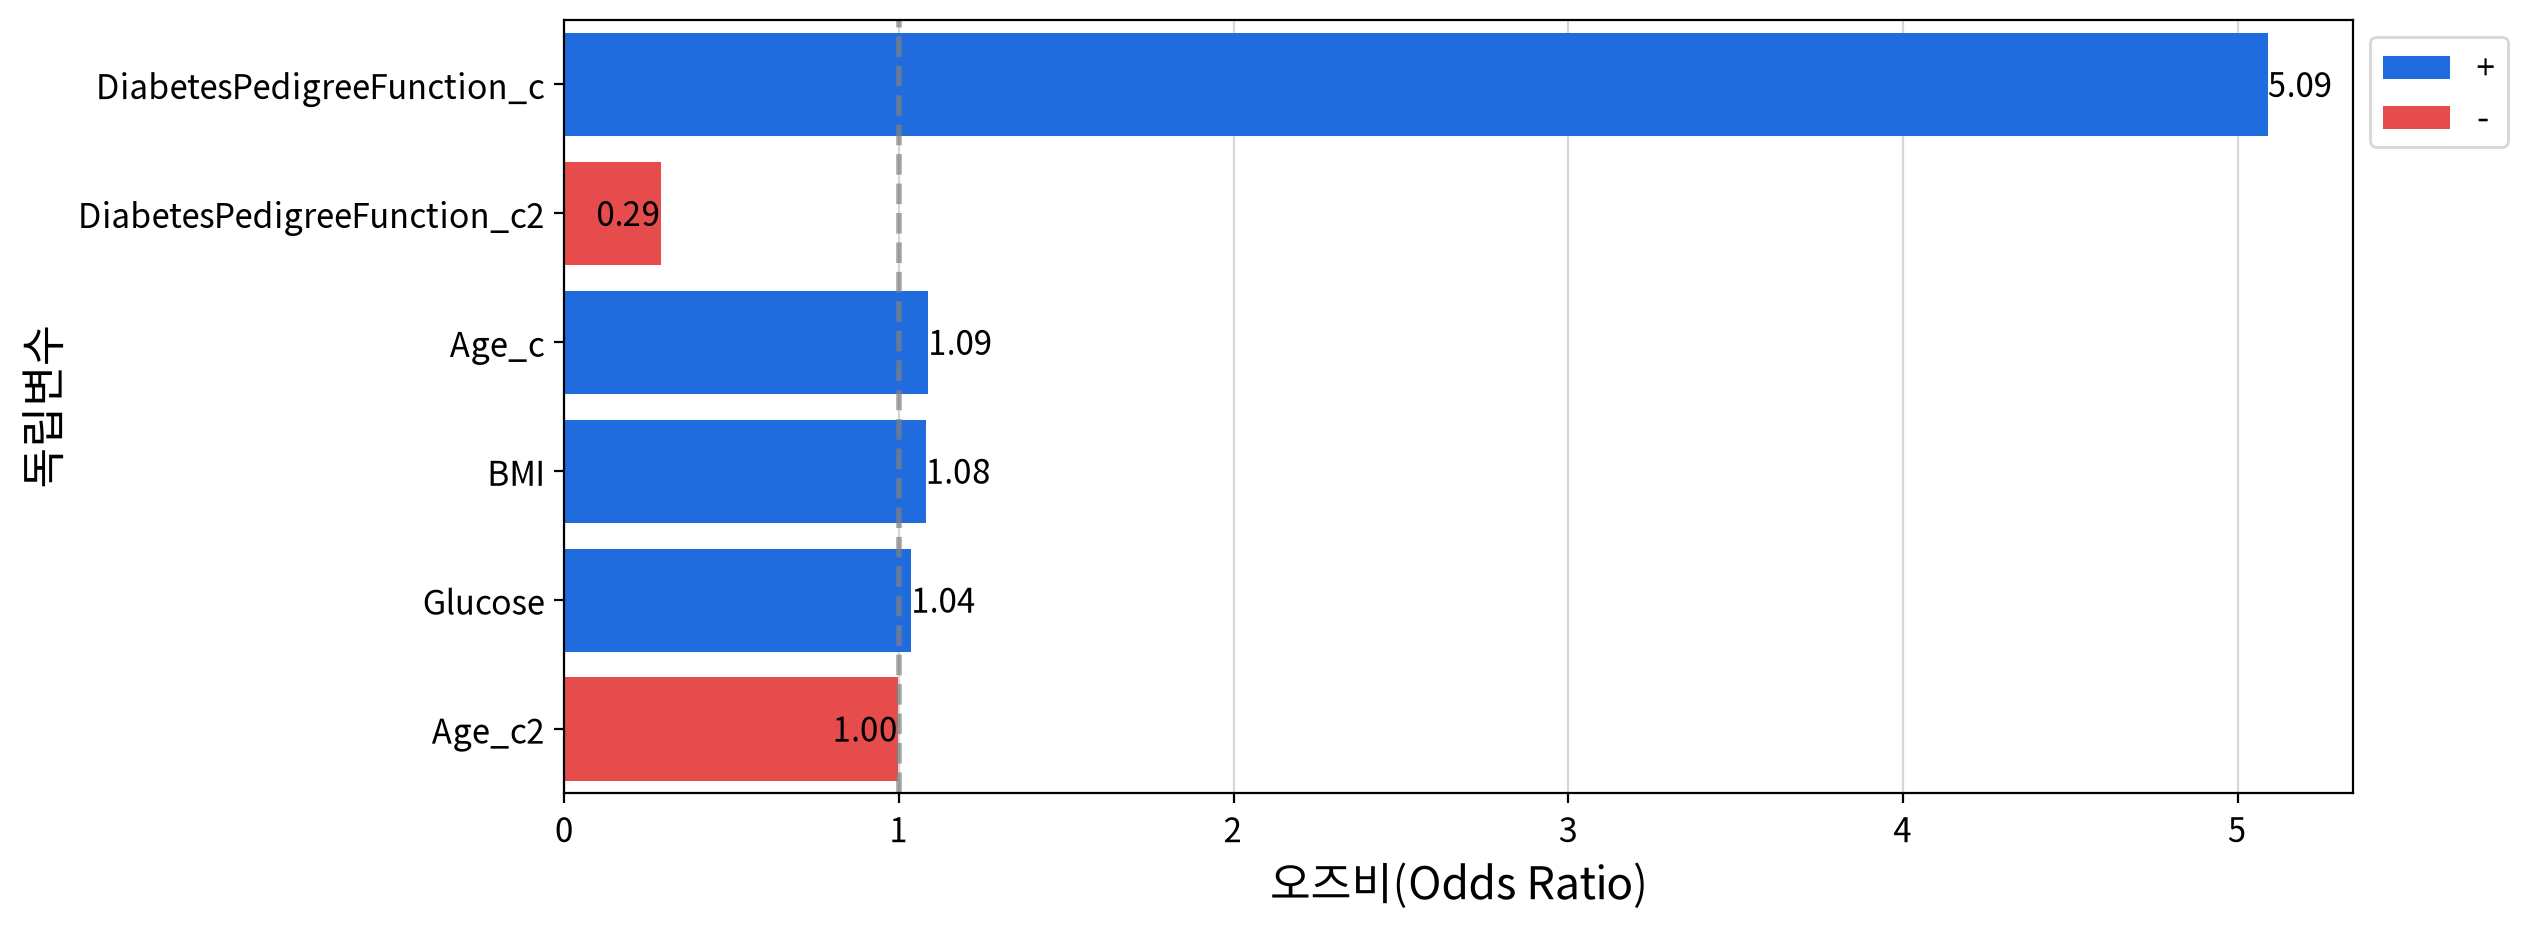

In [87]:
my_logit.auto_logit(data=final_data, y=target)

> ※ **오즈비(OR)의 크기로 변수의 영향력을 비교하면 안 된다.**
> 변수마다 값의 범위가 달라서(혈당 44~199, 가족력 지수 0.08~2.42), 영향력은 범위를 통일한 **표준화 계수(β)** 로 비교한다.

---
##### 💡 인사이트 — 최종 모델

**① 적합도**
- **LLR χ²(6) = 284.63, p < .001, Pseudo R² = 0.305** — 로지스틱 회귀에서 Pseudo R²가 0.2~0.4면 매우 좋은 적합으로 본다.
  - 즉, 독립변수 6개를 넣은 모델이 아무것도 넣지 않은 모델보다 유의하게 낫다.
- **6개 항이 모두 유의**하다(p ≤ 0.004).

<br>

**② 영향력 순위 (표준화 계수 β)**

| 순위 | 변수 | β | 의미 |
|---|---|---|---|
| 1 | `Glucose` | 1.111 | 혈당이 높을수록 당뇨 위험 ↑ |
| 2 | `Age` (1차항) | 0.988 | 나이가 들수록 위험 ↑ (단, 곡선 — 아래 ④) |
| 3 | `DiabetesPedigreeFunction` (1차항) | 0.541 | 가족력이 강할수록 위험 ↑ (단, 곡선 — 아래 ④) |
| 4 | `BMI` | 0.532 | 비만할수록 위험 ↑ |

- **혈당 · 나이 · 가족력 · 체중이 당뇨 위험의 4대 요인**이다. 기준선 모형에서 유의하지 않았던 **나이가 2위**로 올라섰다.

<br>

**③ 직선 관계 — 오즈비로 해석**

| 변수 | 오즈비 | 해석 |
|---|---|---|
| `Glucose` | 1.037 | 혈당 1mg/dL ↑ → 당뇨 오즈 **3.7% 증가** (10 ↑ → 약 43% 증가) |
| `BMI` | 1.080 | BMI 1 ↑ → 당뇨 오즈 **8.0% 증가** |

<br>

**④ 곡선 관계 — 모양으로 해석**
- 제곱항이 있는 변수는 1차항과 제곱항이 **함께** 곡선을 만들어서, 오즈비 하나로 해석하지 않는다.
- 제곱항 B가 **양수면 ∪(아래로 볼록)**, **음수면 ∩(위로 볼록)** 이다.

| 변수 | 1차항 B | 제곱항 B | 모양 | 해석 |
|---|---|---|---|---|
| `Age` | +0.084 | −0.0037 | ∩ | 나이가 들수록 위험이 오르다가, **어느 나이를 넘으면 오히려 낮아진다** |
| `DiabetesPedigreeFunction` | +1.627 | −1.239 | ∩ | 가족력이 강할수록 위험이 크게 오르다가, **아주 높은 구간에서는 다시 낮아진다** |

- 나이가 직선 모형에서 유의하지 않았던 이유가 여기 있다. **오르다가 내려가는 ∩자**라서, 직선 하나로 그으면 기울기가 거의 평평해진다.
- ⚠️ 꼭대기 이후 위험이 낮아지는 구간은 **해석에 주의**해야 한다.
  - 나이 : 고령 표본이 적고, 이미 당뇨가 발병한 고령자가 검진 대상에서 빠졌을 수 있다. '나이 들면 당뇨 위험이 줄어든다'고 일반화해서는 안 된다.
  - 가족력 지수 : 아주 높은 값을 가진 사람이 소수라, 그 구간의 추정은 불안정하다.

<br>

**⑤ 기준선 모형과 무엇이 달라졌나**

| 변수 | 기준선 모형 (직선) | 최종 모델 (곡선 반영) |
|---|---|---|
| `Age` | ❌ 유의하지 않음 (p = 0.085) | ✅ **β 2위** (z = 6.67) |
| `Pregnancies` | ✅ 유의 (p < 0.001) | ❌ 후진소거 제거 (p = 0.235) |

- 나이의 곡선 효과를 제대로 넣자, **임신 횟수의 효과는 사라졌다.** 임신 횟수는 나이와 상관이 있어(r = 0.617), 직선 모형에서는 **나이의 효과를 대신 짊어지고 있었던** 것이다.

---

### (2) 분류 성능 평가

,예측 0 (Negative),예측 1 (Positive)
실제 0 (Negative),418,57
실제 1 (Positive),101,148


,정확도(Accuracy),정밀도(Precision),"재현율(Recall,TPR)","위양성율(Fallout,FPR)","특이성(Specificity,TNR)",F1,AUC,AUC 판단,진단오즈비(DOR)
performance,0.782,0.722,0.594,0.120,0.880,0.652,0.854,판별력 우수,10.746


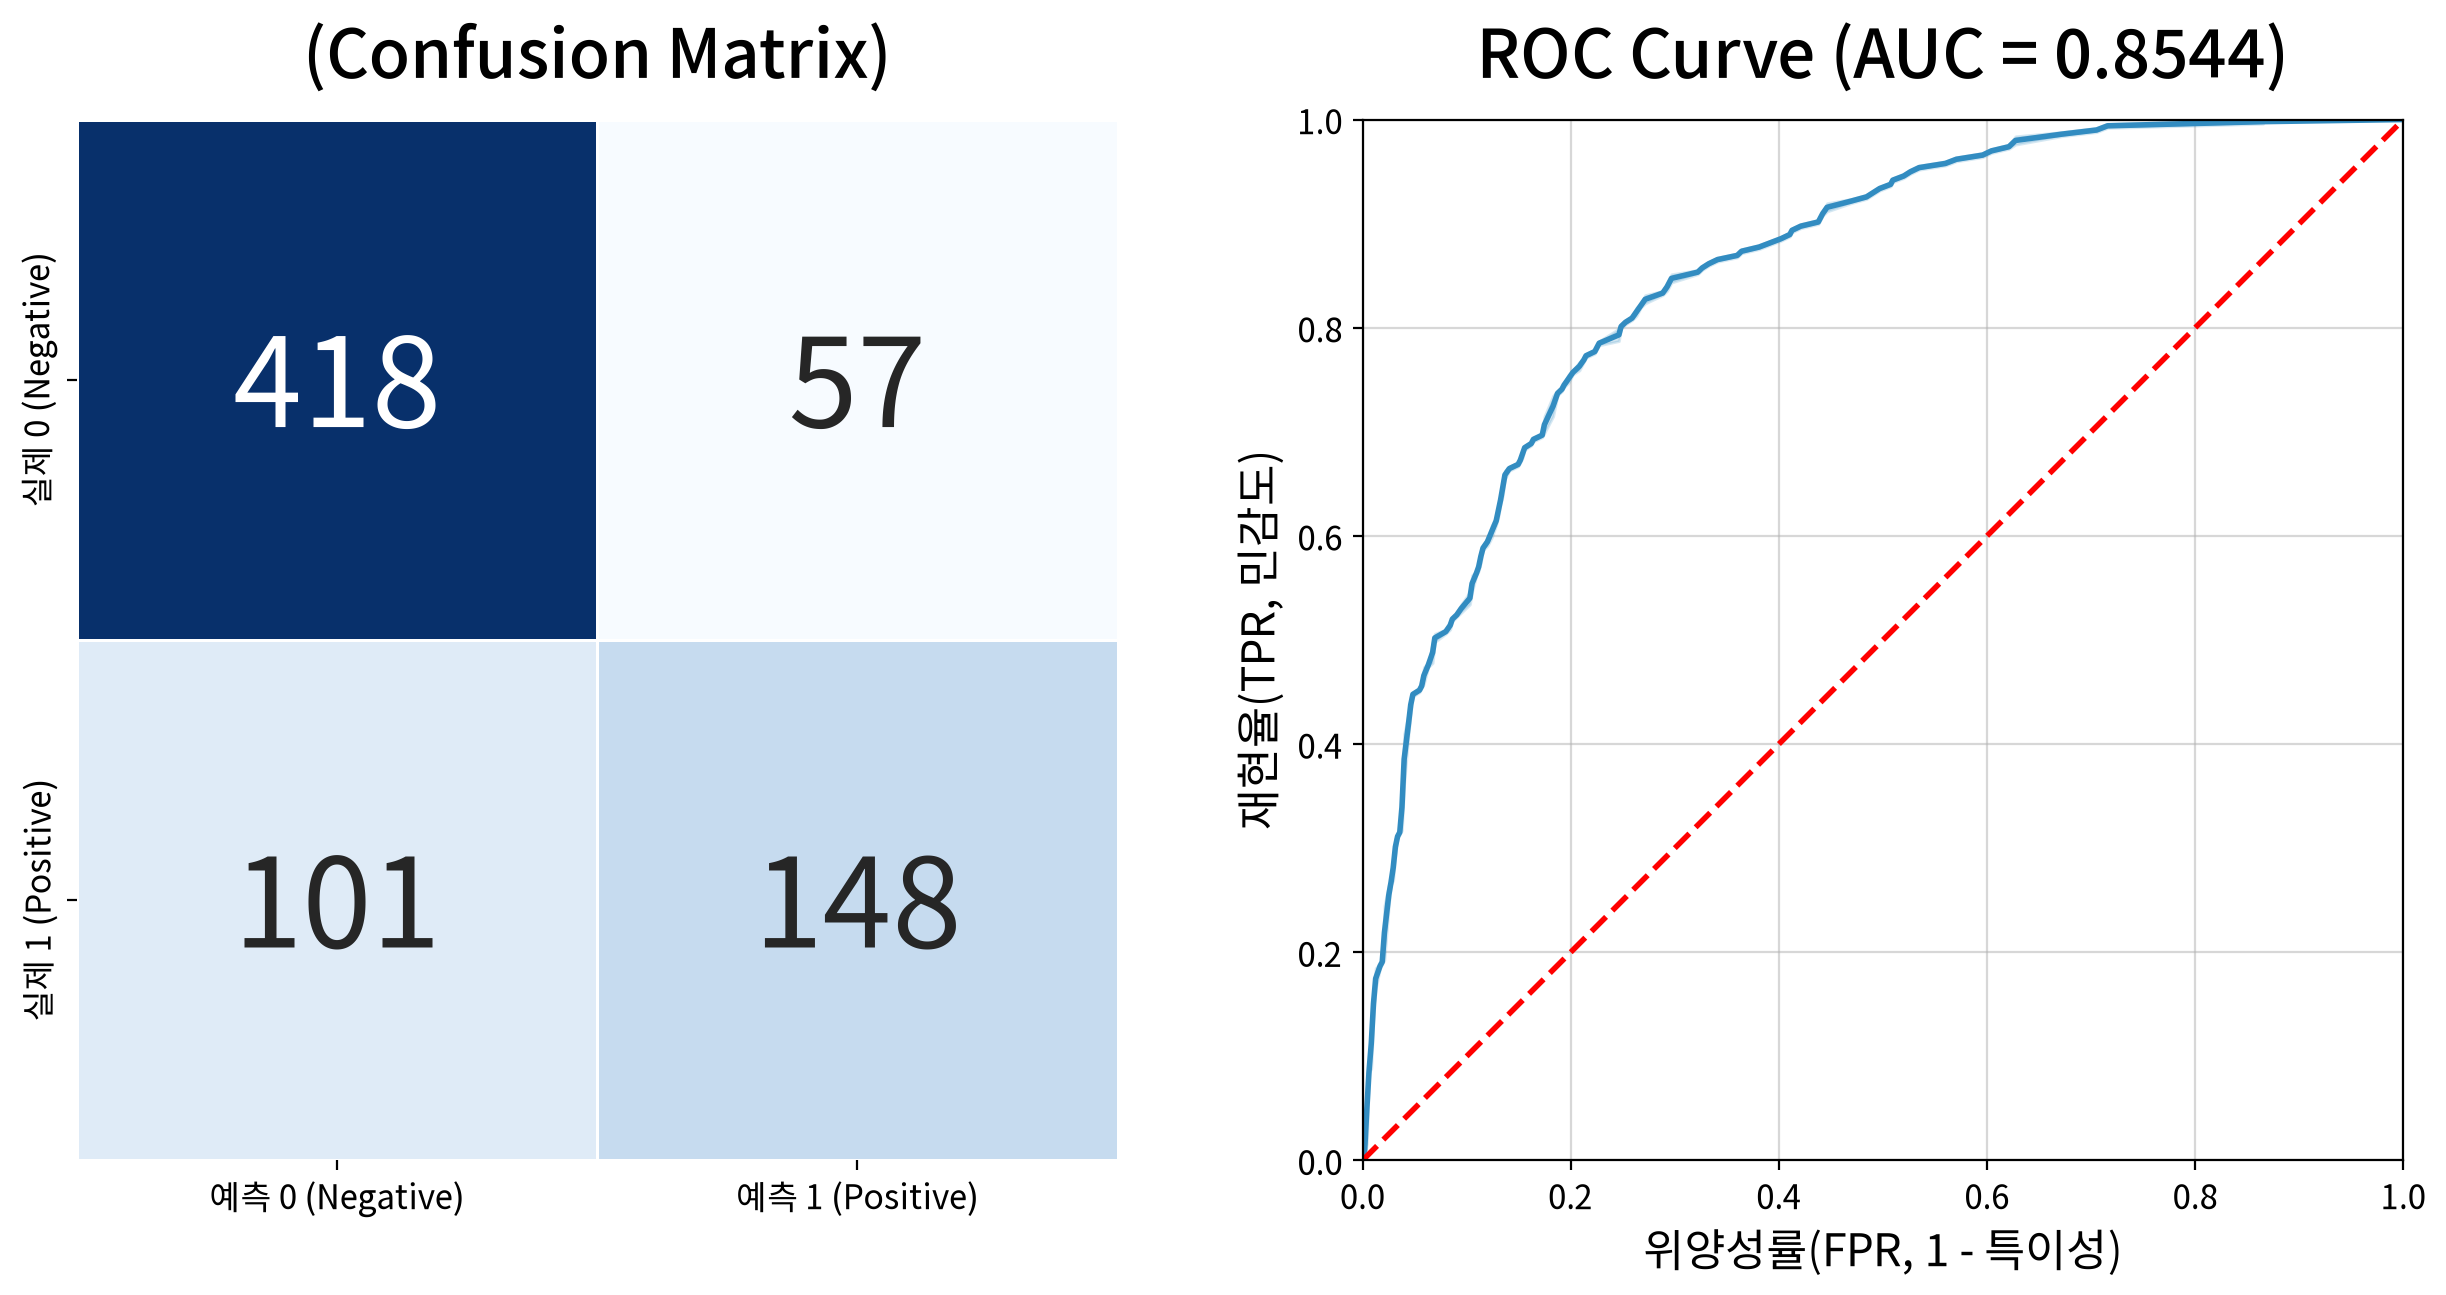

In [88]:
my_logit.report_performance(final_fit)

---
##### 💡 인사이트 — 정확도는 높지만 환자를 놓친다

| 지표 | 값 | 의미 |
|---|---|---|
| 정확도 | 0.782 | 724명 중 566명을 맞혔다. 게으른 모델의 바닥값(65.6%)보다 **12.6%p 높다** |
| 정밀도 | 0.722 | 당뇨로 판정한 사람 중 72.2%가 실제 환자 |
| **재현율** | **0.594** | **당뇨 환자 249명 중 148명만 찾아냈다. 101명(40.6%)을 놓쳤다** |
| 위양성률 | 0.120 | 정상인의 12.0%를 당뇨로 잘못 판정했다 (= 1 − 특이성) |
| 특이성 | 0.880 | 정상인의 88.0%를 정상으로 맞혔다 |
| F1 | 0.652 | 정밀도와 재현율의 균형 점수. 정상인을 많이 맞혀 높아 보였던 정확도(0.782)보다 **훨씬 낮다** → 환자를 찾는 실력은 정확도보다 낮다 |
| AUC | 0.854 | 당뇨 환자 한 명과 정상인 한 명을 무작위로 뽑았을 때, 모델이 환자 쪽에 더 높은 확률을 줄 가능성 **85.4% (우수)** |
| 진단 오즈비 | 10.75 | 당뇨로 판정한 사람이 실제 당뇨일 오즈가, 정상으로 판정한 사람의 **약 10.7배** |

<br>

- ⚠️ **재현율 0.594 — 당뇨 환자 249명 중 101명(40.6%)을 놓쳤다.**
  - 특이성(0.880)은 높은데 재현율은 낮다. 정상인이 약 2배 많은 불균형 데이터라, 모델이 '정상' 쪽으로 판정하는 경향이 있다.
  - 당뇨 **선별검사**라면 환자를 놓치는 것(FN)이 정상인을 정밀검사로 보내는 것(FP)보다 훨씬 큰 손실이다. 정확도만 보고 이 모델을 그대로 쓰면 **환자 10명 중 4명을 놓친다.** → 임계값을 조정한다.

---

### (3) 임계값 조정

- 임계값 0.5는 관례일 뿐 **정답이 아니다.** 목적에 따라 조정한다.
- `FN`은 실제 당뇨인데 정상으로 판정한 환자(**놓친 환자**), `FP`는 실제 정상인데 당뇨로 판정한 사람(**불필요한 정밀검사**)이다.

In [89]:
my_logit.report_threshold(final_fit)

,정확도,정밀도,재현율,F1,FN (놓침 : 실제1→예측0),FP (헛짚음 : 실제0→예측1)
임계값,,,,,,
0.300,0.762,0.616,0.819,0.703,45,127
0.400,0.783,0.674,0.715,0.694,71,86
0.500,0.782,0.722,0.594,0.652,101,57
0.600,0.782,0.783,0.506,0.615,123,35
0.700,0.769,0.831,0.414,0.552,146,21


---
##### 💡 인사이트 — 선별검사라면 임계값을 낮춘다

| 임계값 | 재현율 | 정밀도 | 놓친 환자 (FN) | 불필요한 정밀검사 (FP) | F1 |
|---|---|---|---|---|---|
| 0.3 | **0.819** | 0.616 | **45명** | 127명 | **0.703** |
| 0.4 | 0.715 | 0.674 | 71명 | 86명 | 0.694 |
| 0.5 (기본) | 0.594 | 0.722 | 101명 | 57명 | 0.652 |

- 임계값을 0.5 → **0.3**으로 낮추면 **놓친 환자가 101명 → 45명으로 절반 이하**가 된다. 대신 정밀검사를 받을 정상인이 57명 → 127명으로 늘어난다.
- **F1(정밀도와 재현율의 균형)도 0.3에서 최대(0.703)** 이고, 정확도는 0.782 → 0.762로 2%p만 낮아진다.
- **정답은 목적이 정한다.**
  - **선별검사**(환자를 놓치면 안 됨) → 임계값 **0.3** : 놓친 환자를 최소화
  - **확진 전 우선순위 분류**(정밀검사 자원이 한정됨) → 임계값 **0.5 이상** : 정밀도 확보

---

# 📌 종합 인사이트

### 1. 당뇨 위험의 4대 요인은 혈당 · 나이 · 가족력 · 체중
- 표준화 계수 β 기준 **`Glucose`(1.111) > `Age`(0.988) > `DiabetesPedigreeFunction`(0.541) > `BMI`(0.532)** 다.
- 혈당이 10mg/dL 높으면 당뇨 오즈가 약 43%, BMI가 1 높으면 약 8% 증가한다.

### 2. 직선 모형은 나이의 위험을 지웠다
- 기준선 모형에서 나이는 **유의하지 않았다**(p = 0.085). 직선만 가정하면 그대로 제거됐을 변수다.
- 로짓 선형성 검정이 '직선이 아니다'를 잡아냈고, 제곱항을 넣자 **오르다가 꺾이는 ∩자 관계**가 드러나 **β 2위의 위험요인**이 됐다.
- 동시에 **임신 횟수의 효과는 사라졌다.** 나이와 얽혀 있던 임신 횟수가 직선 모형에서 나이의 효과를 대신 짊어지고 있었던 것이다.
- → **가정 검정은 형식적인 절차가 아니라 결론을 바꾸는 단계**다.

### 3. 자동 선택은 가정을 모른다
- `compare_models()`는 **`2_이상치대체`를 1순위**로 골랐다. AUC가 최고 모델과 1.72% 차이로 5% 이내이고, 변수가 4개로 가장 적었기 때문이다. 하지만 이 모델은 **로짓 선형성 처방을 반영하지 않아, 나이가 '유의하지 않다'며 지워진 모델**이다.
- 따라서 가정을 충족한 모델 안에서, 처방(제곱항)을 지우지 않은 **`5_가정반영+후진소거`** 를 최종 채택했다.
- → **성능 비교표의 1순위는 출발점일 뿐, 가정과 원칙에 비춰 분석자가 검토해야 한다.**

### 4. 정확도 0.78의 함정 — 환자의 40%를 놓친다
- 정상인이 2배 많은 불균형 데이터라, 게으른 모델도 정확도 65.6%가 나온다.
- 기본 임계값(0.5)에서는 **당뇨 환자 249명 중 101명을 놓친다**(재현율 0.594).
- **선별검사 목적이라면 임계값을 0.3으로 낮춰** 놓친 환자를 45명으로 줄이는 것이 맞다(재현율 0.819, F1 최대).

### ⚠️ 한계
- **고령 구간의 해석에 주의해야 한다.** 일정 나이를 넘으면 위험이 낮아지는 곡선은, 고령 표본이 적고 이미 발병한 고령자가 빠진 **표본 특성**일 가능성이 크다.
- **처방이 자동 규칙(AIC)으로 정해졌다.** 가족력 지수는 제곱항이 선택됐지만, 의학적으로는 '가족력이 강할수록 위험이 계속 오른다'는 로그 형태가 더 자연스럽다. 꼭대기 이후 구간은 표본이 적어 불안정하다.
- **결측 처리로 정보를 잃었다.** 인슐린(48.7%) · 피부두께(29.6%)를 제거했는데, 인슐린은 당뇨와 직접 관련된 지표다. 결측 대체(다중대체 등)를 시도해 볼 수 있다.
- **특정 집단의 데이터다.** 21세 이상 피마 인디언 여성만 포함되어, 다른 인종 · 성별에 그대로 일반화할 수 없다.
- **성능을 학습 데이터에서 측정했다(in-sample).** train/test 분할이나 교차검증으로 확인해야 한다.
- **인과관계가 아니라 연관관계다.**

### ✅ 최종 모델
| 항목 | 값 |
|---|---|
| 모델 | `5_가정반영+후진소거` |
| 형태 | `logit(P(당뇨))` ~ `Glucose` + `BMI` + `Age` (1차 · 제곱) + `DiabetesPedigreeFunction` (1차 · 제곱) |
| 성능 (임계값 0.5) | 정확도 0.782 · AUC 0.854 · 재현율 0.594 · Pseudo R² 0.305 |
| 권장 임계값 (선별검사) | 0.3 → 재현율 0.819 · F1 0.703 |
| 가장 큰 영향 | `Glucose` (β = 1.111) |